# Predicting the labour force status of young Rwandans from survey microdata

**Machine Learning summative project — African Leadership University**

| Resource | Link |
|---|---|
| GitHub repository | _add link_ |
| Google Drive (raw data zip + saved models) | _add link_ |
| Video presentation | _add link_ |

## Problem

Young people aged 16–30 are the largest group in Rwanda's working-age population, and they carry a
disproportionate share of its unemployment and labour under-utilisation. For anyone designing
career-readiness programmes it matters *which* young people end up employed, which are searching
without success, and which are outside the labour force altogether (studying, caring, discouraged
or producing only for their own household). This notebook treats that as a **three-class
classification problem** on the Rwanda Labour Force Survey (NISR): given a young person's education,
vocational training, disability, migration history, household position and unpaid domestic work,
predict their ILO labour force status.

Two modelling paradigms are compared on exactly the same data and preprocessing:

1. **Traditional machine learning** with scikit-learn (logistic regression, random forest,
   gradient boosting with XGBoost / LightGBM, and an RBF support-vector machine), with hyper-parameter search.
2. **Deep learning** with TensorFlow/Keras (multilayer perceptrons built with the Functional API,
   including entity embeddings for categorical variables), fed through `tf.data` pipelines and
   logged to TensorBoard.

Convolutional networks are not used: they exploit spatial locality in images, and survey rows have
no such structure (column order is arbitrary), so an MLP is the appropriate neural architecture.

All reusable logic is defined once in the helper cells of Section 0 (configuration, preprocessing,
evaluation, traditional and deep models) so that each experiment cell stays short and the notebook
runs on its own, locally or on Colab.

## 0. Setup

The notebook runs in two environments without edits:

* **Locally**: create the environment from `requirements.txt` (see README) and open this file from
  the `notebooks/` folder.
* **Google Colab**: the next cell mounts Google Drive, installs the two packages Colab lacks, and
  copies the Stata files from the Drive folder (`<DRIVE_PROJECT_DIR>/data/`, either the `.dta` files
  or the zipped raw dataset). Nothing else is needed: the notebook is self-contained. At the end of the notebook all outputs — the
  experiment table, figures, TensorBoard logs and saved models — are copied back to
  `<DRIVE_PROJECT_DIR>/outputs/` as evidence of the run.

Random seeds are fixed in the configuration helper and applied to NumPy, Python and TensorFlow.

In [1]:
# --- Colab bootstrap (no effect when running locally) -----------------------------------------
import os, sys, subprocess, shutil, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
DRIVE_PROJECT_DIR = "ALU_ML_Summative"   # folder in My Drive holding data/ (zip or .dta files)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyreadstat", "tabulate"], check=True)
    drive_dir = Path("/content/drive/MyDrive") / DRIVE_PROJECT_DIR
    work = Path("/content/alu-summative-iml"); (work / "notebooks").mkdir(parents=True, exist_ok=True)
    os.chdir(work / "notebooks")
    Path("../data/raw").mkdir(parents=True, exist_ok=True)
    for z in sorted(drive_dir.glob("data/*.zip")):
        with zipfile.ZipFile(z) as zf:
            for member in zf.namelist():
                if member.endswith(".dta") and not (Path("../data/raw") / Path(member).name).exists():
                    with zf.open(member) as src, open(Path("../data/raw") / Path(member).name, "wb") as dst:
                        shutil.copyfileobj(src, dst)
    for f in sorted(drive_dir.glob("data/*.dta")):
        if not (Path("../data/raw") / f.name).exists():
            shutil.copy(f, "../data/raw/")
    print("Colab setup complete. Raw files:", sorted(p.name for p in Path("../data/raw").glob("*.dta")))

In [2]:
import sys, os, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf, sklearn
print("TensorFlow", tf.__version__, "| scikit-learn", sklearn.__version__)

I0000 00:00:1792348674.822901 1076759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792348674.823383 1076759 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792348678.135388 1076759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792348678.135675 1076759 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | scikit-learn 1.9.1


### 0.1 Helper code

Everything reusable is defined once here, in five groups, so the experiment cells below stay short.
These helpers are plain functions (no hidden package): configuration, preprocessing, evaluation,
traditional models and deep-learning models.

#### Configuration: paths, seed, population, target and feature groups

Project-wide constants: paths, seeds, target definition and feature groups.

Variable names refer to the Rwanda Labour Force Survey (RLFS) public-use
microdata produced by the National Institute of Statistics of Rwanda (NISR),
annual files 2024 and 2025 (``RW_LFS2024.dta``, ``RW_LFS2025.dta``).
See ``data/raw/RW_LFS2024_variables.tsv`` for the full variable list.

In [3]:
from pathlib import Path

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
LOGS_DIR = ROOT / "logs"
FIGURES_DIR = ROOT / "reports" / "figures"
EXPERIMENTS_CSV = ROOT / "reports" / "experiments.csv"

RAW_GLOB = "RW_LFS*.dta"  # every annual round found in data/raw is pooled

SEED = 42

# ---------------------------------------------------------------------------
# Population and target
# ---------------------------------------------------------------------------
AGE_COL = "A04"
YOUTH_MIN_AGE, YOUTH_MAX_AGE = 16, 30  # NISR / Rwanda National Youth Policy definition ("young", YA == 1)

TARGET_COL = "status1"  # ILO labour force status, derived by NISR for persons 16+
TARGET_CODES = {1: 0, 2: 1, 3: 2}  # raw code -> class index
TARGET_NAMES = {
    0: "Employed",
    1: "Unemployed",
    2: "Outside labour force",
}
CLASS_LABELS = [TARGET_NAMES[k] for k in sorted(TARGET_NAMES)]
N_CLASSES = len(TARGET_NAMES)

# ---------------------------------------------------------------------------
# Feature groups (raw survey variables)
# ---------------------------------------------------------------------------
# Rule: only characteristics that are determined BEFORE the labour-market
# outcome may be used. Sections C (activity last 7 days, job search), D (main
# job), F (previous job / income source), H (own-use production) and every
# NISR-derived labour indicator (UR1, LFPR, TRU, PLF, LUU, neet*, IEV2, ...)
# define the target and are excluded.

NUMERIC_FEATURES = [
    "A04",    # age
    "A16Y",   # years since last move to current residence (NaN if never moved)
    "A19",    # years lived in previous location
    "B02B",   # years completed in highest level attended
    "indb1",  # years of schooling (NISR-derived from B02A/B02B)
    "hhsize", # household size (1..10+)
    "G06",    # hours last week on household chores (cooking, shopping, cleaning)
    "G07",    # hours last week caring for children / elderly
    "G01", "G02", "G03", "G04", "G05",  # hours on firewood, water, fodder, goods, construction
]

ORDINAL_FEATURES = [
    "B02A",     # highest education level attended (1 none .. 6 tertiary)
    "attained", # highest level completed (1 none .. 5 university)
    "A06", "A07", "A08", "A09", "A10", "A11",  # Washington-Group disability items (1 none .. 4 cannot)
    "TVT2",     # 1 no level completed, 2 completed general, 3 completed TVET
]

NOMINAL_FEATURES = [
    "province",
    "Code_UR",     # urban / rural
    "code_dis",    # district (30)
    "A01",         # sex
    "A02",         # relationship to household head
    "A05",         # marital status
    "A12",         # nationality
    "A13",         # residential status
    "A15",         # always lived in this district
    "B01",         # currently studying
    "B07",         # currently attending TVET school
    "B08",         # ever learned a TVET course
    "B09",         # TVET course duration (skip-pattern blank = no course)
    "B10",         # type of technical skill learned
    "B13",         # completed TVET course (1 certificate, 2 no certificate, 3 no, 4 ongoing)
    "indb05",      # field of education
    "EN01",        # household lighting energy source (asset / electrification proxy)
    "migrant",     # recent migrant: internal / international / none
    "head",        # household head flag (1 = head, 0 otherwise)
    "disable",     # NISR disability flag
    "age3_16_30",  # 16-19 / 20-24 / 25-30
    "LFS_year",    # survey round (pooled rounds)
]

# Questionnaire items that *define* the target. Used only in the leakage ablation.
LEAKY_FEATURES = ["C01", "C19"]  # paid work last 7 days; looked for work last 4 weeks

WEIGHT_COLS = ["weight2"]

ALL_RAW_COLUMNS = sorted(
    set(NUMERIC_FEATURES + ORDINAL_FEATURES + NOMINAL_FEATURES + LEAKY_FEATURES + WEIGHT_COLS
        + [TARGET_COL, AGE_COL, "YA", "dG01", "dG02", "dG03", "dG04", "dG05", "dG06", "dG07", "TVT", "disable", "pid", "HHID"])
)

# Labels that mark a non-substantive answer in the NISR codebook
SENTINEL_LABEL_PATTERN = r"^(missing|refused|don.?t know|do not know|not applicable|not stated|n/?a)$"

TEST_SIZE = 0.15
VAL_SIZE = 0.15

#### Preprocessing: loading, cleaning, feature engineering, splitting, encoding

Cleaning, feature engineering and train/validation/test splitting for the RLFS.

Pipeline (deterministic given ``config.SEED``):

1. ``load_raw``            read every ``RW_LFS*.dta`` round, keep needed columns, pool
2. ``select_youth``        keep persons aged 16-30 with a valid labour force status
3. ``clean_sentinels``     Missing / Don't know codes -> NaN using the Stata value labels
4. ``engineer_features``   add interpretable composite features
5. ``split``               stratified 70/15/15 split
6. ``build_preprocessor``  sklearn ColumnTransformer fitted on train only

In [4]:
import glob
import re
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# ---------------------------------------------------------------------------
# 1. Loading
# ---------------------------------------------------------------------------

def raw_files(raw_dir=RAW_DIR) -> list[str]:
    return sorted(glob.glob(str(raw_dir / RAW_GLOB)))

def load_raw(raw_dir=RAW_DIR, columns: list[str] | None = None):
    '''Read and pool every RLFS round found. Returns (DataFrame with numeric codes, metadata of the last file).'''
    import pyreadstat

    columns = columns or ALL_RAW_COLUMNS
    frames, meta = [], None
    for path in raw_files(raw_dir):
        _, m = pyreadstat.read_dta(path, metadataonly=True)
        cols = [c for c in columns if c in m.column_names]
        df, meta = pyreadstat.read_dta(path, usecols=cols, apply_value_formats=False)
        year = re.search(r"(20\d{2})", path)
        df["source_file"] = path.rsplit("/", 1)[-1]
        if "LFS_year" not in df.columns or df["LFS_year"].isna().all():
            df["LFS_year"] = int(year.group(1)) if year else np.nan
        frames.append(df)
    if not frames:
        raise FileNotFoundError(f"No {RAW_GLOB} file in {raw_dir}. See data/raw/README.md.")
    return pd.concat(frames, ignore_index=True, sort=False), meta

def value_labels(meta, col: str) -> dict:
    return meta.variable_value_labels.get(col, {}) if meta is not None else {}

# ---------------------------------------------------------------------------
# 2. Population and target
# ---------------------------------------------------------------------------

def select_youth(df: pd.DataFrame) -> pd.DataFrame:
    '''Keep 16-30 year-olds with a valid NISR labour force status; map status to class index.'''
    age_ok = df[AGE_COL].between(YOUTH_MIN_AGE, YOUTH_MAX_AGE)
    target_ok = df[TARGET_COL].isin(list(TARGET_CODES))
    out = df.loc[age_ok & target_ok].copy()
    out[TARGET_COL] = out[TARGET_COL].map(TARGET_CODES).astype(int)
    return out.reset_index(drop=True)

# ---------------------------------------------------------------------------
# 3. Sentinel cleaning
# ---------------------------------------------------------------------------

_SENTINEL_RE = re.compile(SENTINEL_LABEL_PATTERN, flags=re.IGNORECASE)

def sentinel_codes(meta, col: str) -> set[float]:
    return {float(v) for v, lab in value_labels(meta, col).items() if _SENTINEL_RE.match(str(lab).strip())}

def clean_sentinels(df: pd.DataFrame, meta, columns: list[str] | None = None) -> pd.DataFrame:
    out = df.copy()
    columns = columns or [c for c in out.columns if meta is not None and c in meta.column_names]
    report = {}
    for col in columns:
        codes = sentinel_codes(meta, col)
        if col == AGE_COL:
            codes |= {98.0, 99.0}
        if codes:
            mask = out[col].isin(codes)
            if mask.any():
                report[col] = int(mask.sum())
                out.loc[mask, col] = np.nan
    out.attrs["sentinel_report"] = report
    return out

# ---------------------------------------------------------------------------
# 4. Feature engineering
# ---------------------------------------------------------------------------

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    '''Add composite, interpretable features (documented inline).'''
    out = df.copy()

    # Several Stata columns arrive as strings; coerce every numeric feature.
    for col in NUMERIC_FEATURES + ["dG01", "dG02", "dG03", "dG04", "dG05", "dG06", "dG07", "head", "disable", "TVT"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    # Flag variables are coded 1 = yes and blank = no (skip pattern), so blank means 0.
    for col in ["dG01", "dG02", "dG03", "dG04", "dG05", "dG06", "dG07", "head"]:
        if col in out.columns:
            out[col] = out[col].fillna(0.0)

    # Hours are only asked when the activity was done: blank hours with flag 0 mean zero hours.
    for k in range(1, 8):
        h, flag = f"G0{k}", f"dG0{k}"
        if h in out.columns and flag in out.columns:
            out[h] = out[h].where(out[h].notna() | (out[flag] != 0), 0.0)

    # care_hours: unpaid domestic + care work last week (chores + child/elder care)
    out["care_hours"] = out[["G06", "G07"]].sum(axis=1, min_count=1)
    # unpaid_work_hours: all seven own-use service activities
    out["unpaid_work_hours"] = out[[f"G0{k}" for k in range(1, 8)]].sum(axis=1, min_count=1)

    # any_disability / severe_disability from the six Washington-Group items
    wg = out[["A06", "A07", "A08", "A09", "A10", "A11"]]
    out["any_disability"] = (wg.max(axis=1) >= 2).astype(float).where(wg.notna().any(axis=1))
    out["severe_disability"] = (wg.max(axis=1) >= 3).astype(float).where(wg.notna().any(axis=1))

    # tertiary: attended tertiary education
    out["tertiary"] = (out["B02A"] == 6).astype(float).where(out["B02A"].notna())
    # tvet_completed: completed a TVET course with or without certificate
    out["tvet_completed"] = out["B13"].isin([1, 2]).astype(float).where(out["B08"].notna())
    # is_student
    out["is_student"] = (out["B01"] == 1).astype(float).where(out["B01"].notna())

    # schooling_gap: potential years of schooling (age - 6) minus years completed;
    # a large gap flags early school-leaving relative to age
    out["schooling_gap"] = (out["A04"] - 6 - out["indb1"]).clip(lower=0)

    # never_moved: A15 == 1 (always lived in this district); years since move = 0
    out["never_moved"] = (out["A15"] == 1).astype(float).where(out["A15"].notna())
    out["A16Y"] = out["A16Y"].where(out["A15"] != 1, 0.0)
    out["A19"] = out["A19"].where(out["A15"] != 1, 0.0)

    # married_female: interaction that the literature singles out for labour supply
    out["married_female"] = ((out["A01"] == 2) & out["A05"].isin([1, 2, 3])).astype(float).where(out[["A01", "A05"]].notna().all(axis=1))

    # migrant: NaN means "not a recent migrant" -> explicit code 0
    out["migrant"] = out["migrant"].fillna(0)
    # B09/B10/B13 are skip-pattern blanks for people without TVET: keep NaN (indicator) for
    # ordinal B09/B13 and an explicit category for nominal B10 (handled by the encoder).
    return out

ENGINEERED_NUMERIC = [
    "care_hours",
    "unpaid_work_hours",
    "any_disability",
    "severe_disability",
    "tertiary",
    "tvet_completed",
    "is_student",
    "schooling_gap",
    "never_moved",
    "married_female",
]
ENGINEERED_NOMINAL: list[str] = []

# ---------------------------------------------------------------------------
# 5. Splitting
# ---------------------------------------------------------------------------

@dataclass
class Split:
    X_train: pd.DataFrame
    X_val: pd.DataFrame
    X_test: pd.DataFrame
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray

    def summary(self) -> pd.DataFrame:
        rows = {}
        for name, y in [("train", self.y_train), ("val", self.y_val), ("test", self.y_test)]:
            counts = pd.Series(y).value_counts().sort_index()
            rows[name] = {"n": len(y), **{TARGET_NAMES[k]: int(v) for k, v in counts.items()}}
        return pd.DataFrame(rows).T

def make_split(df: pd.DataFrame, feature_cols: list[str], seed: int = SEED) -> Split:
    '''Stratified 70/15/15 split on the target.'''
    X = df[feature_cols]
    y = df[TARGET_COL].to_numpy()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    val_frac = VAL_SIZE / (1 - TEST_SIZE)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=val_frac, stratify=y_tr, random_state=seed)
    return Split(X_tr, X_va, X_te, y_tr, y_va, y_te)

# ---------------------------------------------------------------------------
# 6. Preprocessor
# ---------------------------------------------------------------------------

def feature_lists(engineered: bool = True, include_leaky: bool = False):
    numeric = NUMERIC_FEATURES + ORDINAL_FEATURES + (ENGINEERED_NUMERIC if engineered else [])
    nominal = NOMINAL_FEATURES + (ENGINEERED_NOMINAL if engineered else []) + (LEAKY_FEATURES if include_leaky else [])
    return numeric, nominal

def build_preprocessor(numeric: list[str], nominal: list[str], scale: bool = True, onehot: bool = True) -> ColumnTransformer:
    '''ColumnTransformer: median-impute (+missing indicators) and scale numerics; encode nominals.

    ``onehot=False`` yields integer codes for nominals (used for Keras embeddings).
    '''
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    if onehot:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=20)
    else:
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1)
    # Missing nominal answers (mostly skip patterns, e.g. no TVET course) become their own category.
    cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value=-99)), ("encode", encoder)]
    return ColumnTransformer(
        [("num", Pipeline(num_steps), numeric), ("cat", Pipeline(cat_steps), nominal)],
        verbose_feature_names_out=False,
    )

# ---------------------------------------------------------------------------
# Convenience: full pipeline to a Split
# ---------------------------------------------------------------------------

def prepare(engineered: bool = True, include_leaky: bool = False, raw_dir=RAW_DIR):
    '''Load -> youth filter -> clean -> engineer -> split. Returns (Split, numeric, nominal, meta, youth_df).'''
    df, meta = load_raw(raw_dir)
    df = select_youth(df)
    df = clean_sentinels(df, meta)
    df = engineer_features(df)
    for col in NOMINAL_FEATURES + LEAKY_FEATURES:
        if col in df.columns:
            df[col] = df[col].astype("object")
    numeric, nominal = feature_lists(engineered, include_leaky)
    numeric = [c for c in numeric if c in df.columns]
    nominal = [c for c in nominal if c in df.columns]
    return make_split(df, numeric + nominal), numeric, nominal, meta, df

#### Evaluation: metrics, diagnostic plots and the experiment log

Metrics, diagnostic plots and the experiment log shared by every model.

In [5]:
import json
import time
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import label_binarize

plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight", "font.size": 9})
SHORT_LABELS = ["Employed", "Unemployed", "Outside LF"]

# ---------------------------------------------------------------------------
# Metrics
# ---------------------------------------------------------------------------

def compute_metrics(y_true, y_pred, y_proba=None) -> dict:
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
    }
    if y_proba is not None:
        m["roc_auc_ovr_macro"] = roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro")
        y_bin = label_binarize(y_true, classes=list(range(N_CLASSES)))
        m["pr_auc_macro"] = average_precision_score(y_bin, y_proba, average="macro")
    return {k: round(float(v), 4) for k, v in m.items()}

def per_class_report(y_true, y_pred) -> pd.DataFrame:
    rep = classification_report(y_true, y_pred, target_names=CLASS_LABELS, output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.round(3)

# ---------------------------------------------------------------------------
# Plots
# ---------------------------------------------------------------------------

def plot_confusion(y_true, y_pred, title: str, path: Path | None = None, normalize: str | None = "true"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, norm, sub in zip(axes, [None, normalize], ["counts", "row-normalised"]):
        cm = confusion_matrix(y_true, y_pred, normalize=norm)
        disp = ConfusionMatrixDisplay(cm, display_labels=SHORT_LABELS)
        disp.plot(ax=ax, cmap="Blues", values_format=".2f" if norm else "d", colorbar=False)
        ax.set_title(f"{title} ({sub})")
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

def plot_roc_pr(y_true, y_proba, title: str, path: Path | None = None):
    y_bin = label_binarize(y_true, classes=list(range(N_CLASSES)))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    for k in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, k], y_proba[:, k])
        ax1.plot(fpr, tpr, label=f"{SHORT_LABELS[k]} (AUC={auc(fpr, tpr):.2f})")
        prec, rec, _ = precision_recall_curve(y_bin[:, k], y_proba[:, k])
        ap = average_precision_score(y_bin[:, k], y_proba[:, k])
        ax2.plot(rec, prec, label=f"{SHORT_LABELS[k]} (AP={ap:.2f}, base={y_bin[:, k].mean():.2f})")
    ax1.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax1.set(xlabel="False positive rate", ylabel="True positive rate", title=f"{title}: one-vs-rest ROC")
    ax2.set(xlabel="Recall", ylabel="Precision", title=f"{title}: precision-recall")
    ax1.legend(fontsize=7)
    ax2.legend(fontsize=7)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

def plot_sklearn_learning_curve(estimator, X, y, title: str, path: Path | None = None, cv=3, scoring="f1_macro", n_jobs=-1):
    sizes, tr, va = learning_curve(
        estimator, X, y, cv=cv, scoring=scoring, n_jobs=n_jobs,
        train_sizes=np.linspace(0.1, 1.0, 6), random_state=SEED, shuffle=True,
    )
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.plot(sizes, tr.mean(1), "o-", label="train")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=0.15)
    ax.plot(sizes, va.mean(1), "o-", label="cross-val")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15)
    ax.set(xlabel="training samples", ylabel=scoring, title=f"{title}: learning curve")
    ax.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig, {"sizes": sizes.tolist(), "train": tr.mean(1).round(4).tolist(), "val": va.mean(1).round(4).tolist()}

def plot_keras_history(history: dict, title: str, path: Path | None = None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, key in zip(axes, ["loss", "accuracy"]):
        ax.plot(history[key], label=f"train {key}")
        ax.plot(history[f"val_{key}"], label=f"val {key}")
        ax.set(xlabel="epoch", ylabel=key, title=f"{title}: {key}")
        ax.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

# ---------------------------------------------------------------------------
# Experiment log
# ---------------------------------------------------------------------------

def log_experiment(
    run_id: str,
    approach: str,
    model: str,
    hyperparams: dict,
    val_metrics: dict,
    test_metrics: dict | None = None,
    notes: str = "",
    features: str = "base+engineered",
    logdir: str = "",
    train_time_s: float | None = None,
    path: Path = EXPERIMENTS_CSV,
) -> pd.DataFrame:
    row = {
        "run_id": run_id,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "approach": approach,
        "model": model,
        "features": features,
        "split": "70/15/15 stratified, seed 42",
        "hyperparams": json.dumps(hyperparams, default=str),
        **{f"val_{k}": v for k, v in val_metrics.items()},
        **{f"test_{k}": v for k, v in (test_metrics or {}).items()},
        "train_time_s": round(train_time_s, 1) if train_time_s is not None else None,
        "logdir": logdir,
        "notes": notes,
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(path) if path.exists() else pd.DataFrame()
    df = df[df.get("run_id", pd.Series(dtype=str)) != run_id] if len(df) else df
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(path, index=False)
    return df

def load_experiments(path: Path = EXPERIMENTS_CSV) -> pd.DataFrame:
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

def write_tensorboard_scalars(run_id: str, metrics: dict, hyperparams: dict | None = None, logs_dir: Path = LOGS_DIR) -> str:
    '''Record final metrics (and hyper-parameters as text) for a non-Keras run so every row of the
    experiment table is backed by a TensorBoard log, not only the deep-learning runs.'''
    import tensorflow as tf

    logdir = Path(logs_dir) / run_id
    writer = tf.summary.create_file_writer(str(logdir))
    with writer.as_default():
        for k, v in metrics.items():
            tf.summary.scalar(k, float(v), step=0)
        if hyperparams:
            tf.summary.text("hyperparams", json.dumps(hyperparams, default=str), step=0)
    writer.flush()
    return str(logdir)

#### Traditional models: model zoo and a uniform fit/evaluate helper

Traditional (scikit-learn family) models and a uniform fit/evaluate helper.

In [6]:
import time

import numpy as np
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

def model_zoo(seed: int = SEED) -> dict:
    '''Baseline configurations for each traditional algorithm.'''
    from lightgbm import LGBMClassifier
    from xgboost import XGBClassifier

    return {
        "logreg": LogisticRegression(max_iter=2000, C=1.0, random_state=seed),
        "random_forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=seed),
        "gradient_boosting": GradientBoostingClassifier(random_state=seed),
        "xgboost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                 objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", device="cpu", random_state=seed, n_jobs=-1),
        "lightgbm": LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8,
                                   random_state=seed, n_jobs=-1, verbose=-1),
        "svm_rbf": SVC(C=1.0, kernel="rbf", probability=True, random_state=seed),
    }

def fit_and_evaluate(estimator, preprocessor, split, sample_weight=None):
    '''Fit ``Pipeline(preprocessor, estimator)`` on train; return pipeline, val/test metrics, probabilities, timing.'''
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", clone(estimator))])
    t0 = time.time()
    fit_kwargs = {"model__sample_weight": sample_weight} if sample_weight is not None else {}
    pipe.fit(split.X_train, split.y_train, **fit_kwargs)
    elapsed = time.time() - t0
    out = {"pipeline": pipe, "train_time_s": elapsed}
    for name, X, y in [("val", split.X_val, split.y_val), ("test", split.X_test, split.y_test)]:
        proba = pipe.predict_proba(X)
        pred = proba.argmax(axis=1)
        out[f"{name}_metrics"] = compute_metrics(y, pred, proba)
        out[f"{name}_proba"] = proba
        out[f"{name}_pred"] = pred
    return out

def balanced_sample_weight(y: np.ndarray) -> np.ndarray:
    counts = np.bincount(y, minlength=N_CLASSES).astype(float)
    w = counts.sum() / (N_CLASSES * counts)
    return w[y]

#### Deep learning: tf.data pipelines, Functional-API architectures, training loop

Keras models (Functional API), tf.data input pipelines and TensorBoard logging.

Two input modes are supported:

* ``dense``      a single preprocessed matrix (one-hot nominals), fed to an MLP
* ``embedding``  numeric block + integer-coded nominals, each nominal passed
                 through its own Embedding layer (entity embeddings)

In [7]:
import os
import random
import time
from pathlib import Path

import numpy as np

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def set_seeds(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

# ---------------------------------------------------------------------------
# tf.data pipelines
# ---------------------------------------------------------------------------

def make_dataset(inputs, y, batch_size: int = 256, shuffle: bool = False, seed: int = SEED) -> tf.data.Dataset:
    '''Build a batched, prefetched tf.data.Dataset from numpy inputs (array or dict of arrays).'''
    if isinstance(inputs, dict):
        feats = {k: tf.convert_to_tensor(v) for k, v in inputs.items()}
    else:
        feats = tf.convert_to_tensor(inputs, dtype=tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((feats, tf.convert_to_tensor(y, dtype=tf.int32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(y), 20_000), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def split_embedding_inputs(X_mat: np.ndarray, n_numeric: int, nominal_names: list[str]) -> dict:
    '''Turn a [numeric | ordinal-coded nominal] matrix into the dict the embedding model expects.'''
    out = {"numeric": X_mat[:, :n_numeric].astype(np.float32)}
    for j, name in enumerate(nominal_names):
        out[f"cat_{j}"] = (X_mat[:, n_numeric + j].astype(np.int64) + 1)  # shift so -1 (unknown) -> 0
    return out

# ---------------------------------------------------------------------------
# Architectures
# ---------------------------------------------------------------------------

def build_mlp(
    n_features: int,
    hidden: tuple[int, ...] = (256, 128),
    dropout: float = 0.3,
    batch_norm: bool = True,
    l2: float = 0.0,
    activation: str = "relu",
    name: str = "mlp",
) -> keras.Model:
    '''Plain MLP on a dense preprocessed matrix (Functional API).'''
    reg = keras.regularizers.l2(l2) if l2 else None
    inp = keras.Input(shape=(n_features,), name="features")
    x = inp
    for i, units in enumerate(hidden):
        x = layers.Dense(units, kernel_regularizer=reg, name=f"dense_{i}")(x)
        if batch_norm:
            x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Activation(activation, name=f"act_{i}")(x)
        if dropout:
            x = layers.Dropout(dropout, name=f"drop_{i}")(x)
    out = layers.Dense(N_CLASSES, activation="softmax", name="output")(x)
    return keras.Model(inp, out, name=name)

def build_embedding_mlp(
    n_numeric: int,
    cardinalities: list[int],
    nominal_names: list[str],
    hidden: tuple[int, ...] = (256, 128),
    dropout: float = 0.3,
    batch_norm: bool = True,
    emb_dim_rule=lambda n: int(min(16, max(2, round(1.6 * n ** 0.56)))),
    l2: float = 0.0,
    name: str = "embedding_mlp",
) -> keras.Model:
    '''Entity-embedding MLP: one Embedding per nominal feature, concatenated with numerics.'''
    reg = keras.regularizers.l2(l2) if l2 else None
    num_in = keras.Input(shape=(n_numeric,), name="numeric")
    inputs, branches = [num_in], [num_in]
    for j, (card, nm) in enumerate(zip(cardinalities, nominal_names)):
        cat_in = keras.Input(shape=(1,), dtype="int64", name=f"cat_{j}")
        emb = layers.Embedding(input_dim=card + 1, output_dim=emb_dim_rule(card), name=f"emb_{nm.replace('.', '_')}")(cat_in)
        branches.append(layers.Flatten()(emb))
        inputs.append(cat_in)
    x = layers.Concatenate(name="concat")(branches)
    for i, units in enumerate(hidden):
        x = layers.Dense(units, kernel_regularizer=reg, name=f"dense_{i}")(x)
        if batch_norm:
            x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Activation("relu", name=f"act_{i}")(x)
        if dropout:
            x = layers.Dropout(dropout, name=f"drop_{i}")(x)
    out = layers.Dense(N_CLASSES, activation="softmax", name="output")(x)
    return keras.Model(inputs, out, name=name)

# ---------------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------------

def compile_model(model: keras.Model, lr: float = 1e-3, optimizer: str = "adam", weight_decay: float = 0.0):
    opts = {"adam": keras.optimizers.Adam, "adamw": keras.optimizers.AdamW, "sgd": keras.optimizers.SGD, "rmsprop": keras.optimizers.RMSprop}
    kwargs = {"learning_rate": lr}
    if optimizer == "adamw":
        kwargs["weight_decay"] = weight_decay
    if optimizer == "sgd":
        kwargs["momentum"] = 0.9
    model.compile(optimizer=opts[optimizer](**kwargs), loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
    return model

def class_weights_from(y: np.ndarray) -> dict:
    '''Inverse-frequency class weights, normalised to mean 1.'''
    counts = np.bincount(y, minlength=N_CLASSES).astype(float)
    w = counts.sum() / (N_CLASSES * counts)
    return {i: float(v) for i, v in enumerate(w)}

def train(
    model: keras.Model,
    train_ds: tf.data.Dataset,
    val_ds: tf.data.Dataset,
    run_id: str,
    epochs: int = 100,
    patience: int = 10,
    class_weight: dict | None = None,
    reduce_lr: bool = True,
    logs_dir: Path = LOGS_DIR,
    verbose: int = 0,
):
    '''Fit with early stopping on val_loss, optional LR reduction, and TensorBoard logging.'''
    logdir = Path(logs_dir) / run_id
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.TensorBoard(log_dir=str(logdir), histogram_freq=0),
    ]
    if reduce_lr:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 3), min_lr=1e-6))
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, class_weight=class_weight, verbose=verbose)
    elapsed = time.time() - t0
    history = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    return history, {"epochs_run": len(history["loss"]), "best_epoch": best_epoch, "train_time_s": elapsed, "logdir": str(logdir)}

def predict_proba(model: keras.Model, ds: tf.data.Dataset) -> np.ndarray:
    return model.predict(ds, verbose=0)

In [8]:
set_seeds(SEED)
for d in [PROCESSED_DIR, MODELS_DIR, LOGS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)
if EXPERIMENTS_CSV.exists():
    EXPERIMENTS_CSV.unlink()  # start the experiment table fresh on every full run
print("helpers loaded | seed", SEED, "| raw files:", [p.name for p in RAW_DIR.glob(RAW_GLOB)])

helpers loaded | seed 42 | raw files: ['RW_LFS2024.dta', 'RW_LFS2025.dta']


## 1. Data loading and description

**Source.** Rwanda Labour Force Survey (RLFS) public-use microdata, National Institute of Statistics
of Rwanda (NISR). The survey is a stratified two-stage probability sample of households, conducted
quarterly and pooled into annual files; it is Rwanda's official source for ILO labour-market
indicators. The annual files for 2024 (catalogue entry 114) and, when present, 2025 (entry 125) are
read from `data/raw/` and pooled. They are public-use files obtained after free registration and are
**not** committed to the repository (shared through the Google Drive folder instead).

**Why this dataset.** It is the official, nationally representative survey on exactly the question
this project asks, and it contains the pre-labour-market characteristics that career programmes can
act on: education level and field, vocational training (TVET), disability, migration, household
position and unpaid domestic work. Each annual round has roughly 100,000 persons, of whom about
27,000 are aged 16–30, so the youth sub-sample alone is above the project's 20,000-row threshold.

**Population.** Persons aged 16–30, NISR's definition of "young" (variable `YA`), with a valid
labour force status.

**Target.** `status1`, NISR's ILO-standard labour force status for persons 16+:
*Employed* (did any work for pay or profit in the last week, or temporarily absent),
*Unemployed* (not employed, actively searched in the last four weeks, and available), or
*Outside the labour force* (everyone else: students, home-makers, discouraged job-seekers,
subsistence producers).

In [9]:
df_raw, meta = load_raw()
print("Rounds found:", sorted(df_raw["source_file"].unique()))
print("Raw rows (all ages):", f"{len(df_raw):,}", "| selected columns:", df_raw.shape[1])
ages = pd.to_numeric(df_raw["A04"], errors="coerce")
print(f"Age range {int(ages.min())}–{int(ages.max())}, median {ages.median():.0f}; share aged 16–30: {ages.between(16, 30).mean():.1%}")
display(df_raw.groupby("source_file").size().rename("persons").to_frame().T)

Rounds found: ['RW_LFS2024.dta', 'RW_LFS2025.dta']
Raw rows (all ages): 203,414 | selected columns: 60
Age range 0–95, median 20; share aged 16–30: 26.3%


source_file,RW_LFS2024.dta,RW_LFS2025.dta
persons,102562,100852


Persons aged 16–30 with a valid labour force status: 53,503


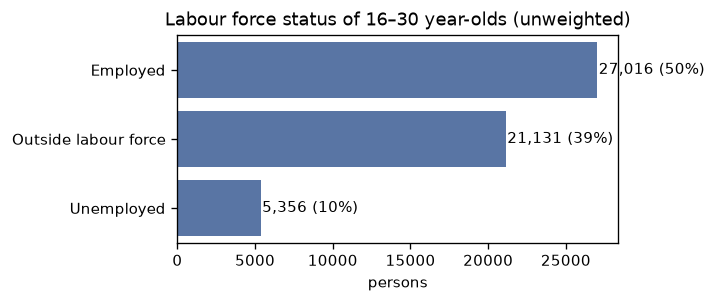

,unweighted share,weighted share
status1,,
Employed,0.505,0.508
Outside labour force,0.395,0.391
Unemployed,0.100,0.101


In [10]:
youth = select_youth(df_raw)
print("Persons aged 16–30 with a valid labour force status:", f"{len(youth):,}")

target_counts = youth[TARGET_COL].map(TARGET_NAMES).value_counts()
fig, ax = plt.subplots(figsize=(6, 2.6))
sns.barplot(x=target_counts.values, y=target_counts.index, ax=ax, color="#4C72B0")
for i, v in enumerate(target_counts.values):
    ax.text(v + 100, i, f"{v:,} ({v/len(youth):.0%})", va="center")
ax.set(xlabel="persons", ylabel="", title="Labour force status of 16–30 year-olds (unweighted)")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig01_target_distribution.png")
plt.show()

# Survey-weighted shares for comparison with NISR's published indicators
w = pd.to_numeric(youth["weight2"], errors="coerce")
weighted = youth.groupby(youth[TARGET_COL].map(TARGET_NAMES)).apply(lambda g: w.loc[g.index].sum()) / w.sum()
display(pd.DataFrame({"unweighted share": target_counts / len(youth), "weighted share": weighted}).round(3))

About half of young Rwandans are employed, four in ten are outside the labour force and only about
one in nine is unemployed in the ILO sense. The minority class is the policy-relevant one, so
accuracy alone would reward a model that never predicts it; we report balanced accuracy, macro-F1,
per-class recall and one-vs-rest ROC-AUC throughout. The weighted shares are close to the
unweighted ones, so the unweighted sample is used for modelling and weights are kept for descriptives.

### 1.1 Exploratory analysis

How labour force status varies with the variables that career programmes can act on: sex,
residence, province, education level, TVET and current studying. Codes are mapped to codebook
labels only for plotting; the modelling pipeline keeps numeric codes.

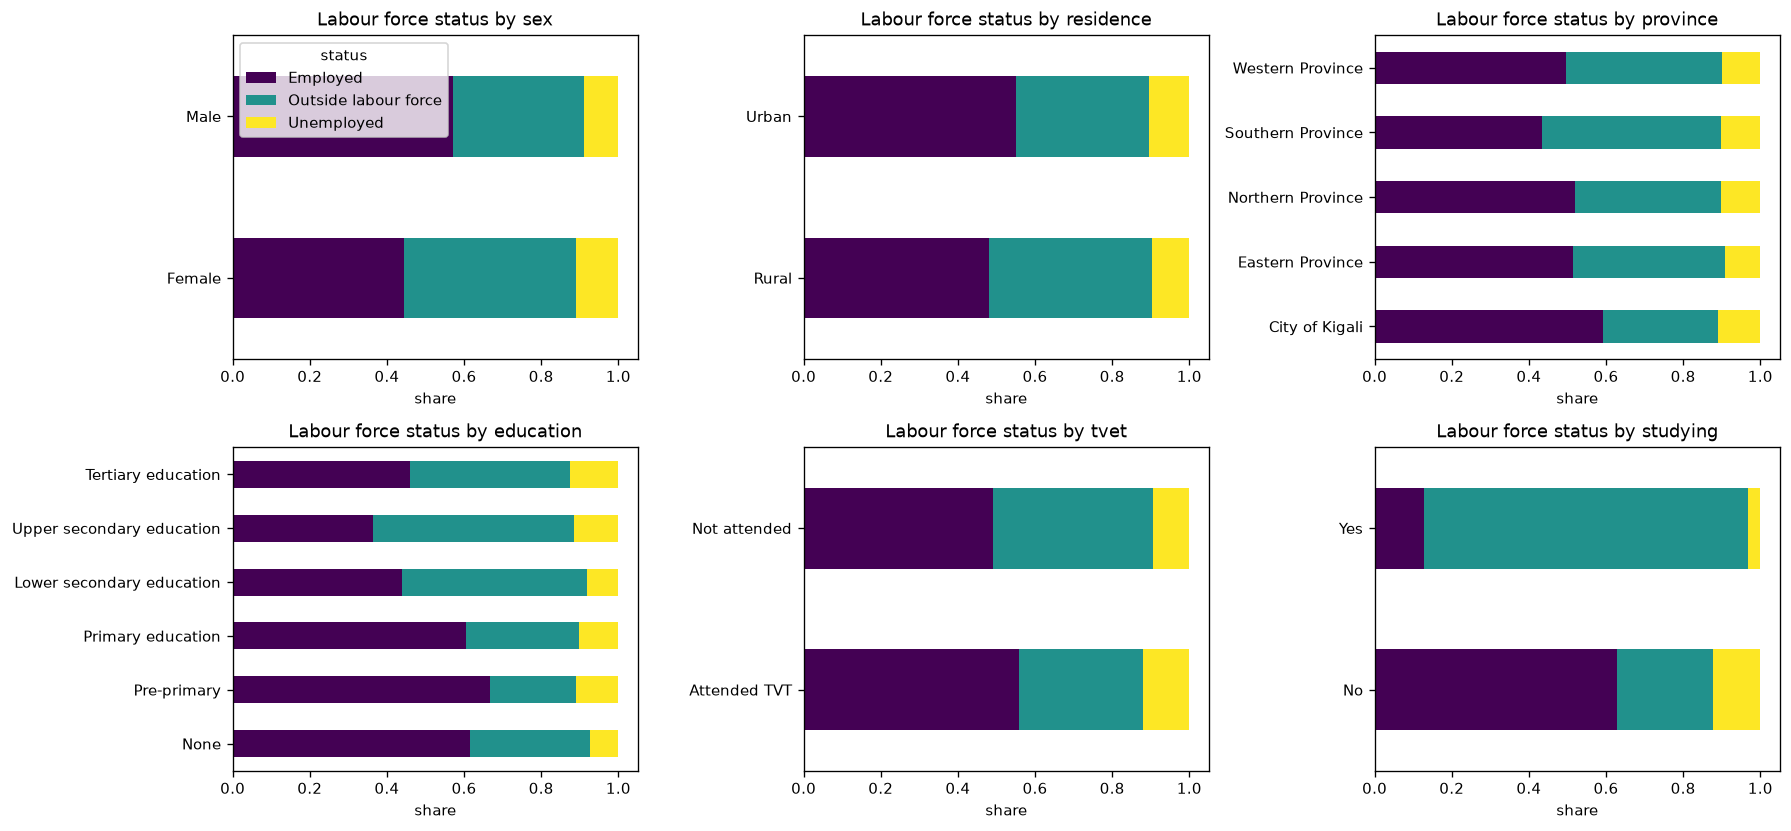

In [11]:
lab = lambda col: pd.to_numeric(youth[col], errors="coerce").map(meta.variable_value_labels[col])
plot_df = pd.DataFrame({
    "status": youth[TARGET_COL].map(TARGET_NAMES),
    "sex": lab("A01"), "residence": lab("Code_UR"), "province": lab("province"),
    "education": lab("B02A"), "tvet": lab("TVT"), "studying": lab("B01"),
    "age group": lab("age3_16_30"),
})
edu_order = ["None", "Pre-primary", "Primary education", "Lower secondary education", "Upper secondary education", "Tertiary education"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["sex", "residence", "province", "education", "tvet", "studying"]):
    ct = pd.crosstab(plot_df[col], plot_df["status"], normalize="index")
    if col == "education":
        ct = ct.reindex([e for e in edu_order if e in ct.index])
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="viridis", legend=(col == "sex"))
    ax.set(title=f"Labour force status by {col}", xlabel="share", ylabel="")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig02_eda_bivariate.png")
plt.show()

In [12]:
ct = pd.crosstab([plot_df["sex"], plot_df["age group"]], plot_df["status"], normalize="index").round(3)
ct["n"] = plot_df.groupby(["sex", "age group"]).size()
display(ct)

status            Employed  Outside labour force  Unemployed     n
sex    age group                                                  
Female 16-19 yrs     0.282                 0.654       0.064  9451
       20-24 yrs     0.481                 0.387       0.132  9658
       25-30 yrs     0.577                 0.287       0.136  8757
Male   16-19 yrs     0.346                 0.585       0.069  9150
       20-24 yrs     0.620                 0.278       0.102  8791
       25-30 yrs     0.785                 0.117       0.098  7696

In [13]:
youth_clean = clean_sentinels(youth, meta)
miss = youth_clean[NUMERIC_FEATURES + ORDINAL_FEATURES + NOMINAL_FEATURES].isna().mean().sort_values(ascending=False)
print("Raw missingness before skip-pattern handling (share of youth rows):")
display(miss.head(10).round(3).rename("share_missing").to_frame().T)

Raw missingness before skip-pattern handling (share of youth rows):


,G04,G05,head,B09,B13,B10,migrant,G03,G01,G07
share_missing,0.988,0.964,0.838,0.785,0.785,0.785,0.773,0.7,0.686,0.683


Three observations shape the preprocessing choices below. First, the raw file has almost no
"Don't know"/"Missing" codes; what looks like missingness is **skip-pattern structure**: TVET
duration and completion are blank for the 80% who never took a course, hours of chores are blank for
people who did none, and the household-head flag is blank for non-heads. Those blanks carry meaning
and are converted to zeros or explicit categories rather than imputed. Second, the share employed
rises with age while the share outside the labour force falls — the 16–19 group is dominated by
students — so age and studying will matter, and the model must not simply learn "student ⇒ outside
the labour force". Third, women and rural residents are shifted towards the outside-labour-force
class rather than towards unemployment, which is where the literature places the care-work burden.

## 2. Preprocessing and feature engineering

The preprocessing helpers are deterministic and fitted on the training split only.

1. **Leakage control (the most important choice).** NISR derives `status1` from questionnaire
   sections C (work in the last 7 days, job search in the last 4 weeks, availability), D (main job),
   F (previous job, income source) and H (own-use production). Every variable in those sections, and
   every NISR-derived labour indicator (unemployment rate, NEET, under-employment, informal
   employment, hours, earnings), *is* the target in another form. All are excluded. Only
   characteristics determined before the labour-market outcome are used. Experiment E09 adds two
   of the defining items back to show what leakage looks like.
2. **Sentinel cleaning.** Codes whose Stata value label is *Missing* or *Don't know* (e.g. 9 in the
   education items, 98 in age) are read from the file's metadata and set to NaN.
3. **Skip patterns.** Blank activity flags and household-head flags mean "no" and become 0; blank
   hours with a "did not do it" flag become 0 hours; blank migration status means "not a recent
   migrant"; blank TVET duration/skill/completion become an explicit "no TVET" category.
4. **Feature groups.** 13 numeric variables (age, years since last move, years in previous
   location, years completed in level, years of schooling, household size, seven unpaid-work hour
   counts), 9 ordered scales (education level attended and completed, six disability items, TVET
   attainment) treated as numeric, and 22 nominal variables (province, district, urban/rural, sex,
   relationship to head, marital status, nationality, residential status, always lived here,
   studying, attending TVET, learned TVET, TVET duration, TVET skill, TVET completion, field of
   education, lighting energy, migrant type, head, disability flag, age group, survey round).
5. **Engineered features** (10), each with a substantive rationale: `care_hours` (chores + care),
   `unpaid_work_hours` (all seven own-use services), `any_disability` and `severe_disability`
   (Washington Group thresholds), `tertiary`, `tvet_completed`, `is_student`,
   `schooling_gap` (potential minus completed years of schooling, a proxy for early leaving),
   `never_moved`, and `married_female` (the interaction the labour-supply literature singles out).
   Their contribution is measured directly by E01 versus E02.
6. **Encoding.** Numerics: median imputation with missing indicators, then standardisation.
   Nominals: explicit missing category, then one-hot encoding (categories with fewer than 20 training
   rows pooled) — or integer codes when feeding Keras embedding layers.
7. **Split.** Stratified 70 / 15 / 15 train / validation / test with seed 42. The validation set
   drives model selection and early stopping; the test set is touched once per final model.

In [14]:
split, numeric, nominal, meta, youth_fe = prepare(engineered=True)
print(f"{len(numeric)} numeric/ordinal features, {len(nominal)} nominal features")
display(split.summary())

prep = build_preprocessor(numeric, nominal)
X_train_mat = prep.fit_transform(split.X_train)
print("Design matrix after one-hot encoding:", X_train_mat.shape)

display(youth_fe[ENGINEERED_NUMERIC].describe().T[["mean", "std", "min", "max"]].round(3))

32 numeric/ordinal features, 22 nominal features


,n,Employed,Unemployed,Outside labour force
train,37451,18910,3750,14791
val,8026,4053,803,3170
test,8026,4053,803,3170


Design matrix after one-hot encoding: (37451, 191)


,mean,std,min,max
care_hours,7.691,10.560,0.0,105.0
unpaid_work_hours,13.578,14.643,0.0,114.0
any_disability,0.029,0.168,0.0,1.0
severe_disability,0.014,0.117,0.0,1.0
tertiary,0.056,0.230,0.0,1.0
tvet_completed,0.096,0.294,0.0,1.0
is_student,0.246,0.431,0.0,1.0
schooling_gap,8.791,5.180,0.0,24.0
never_moved,0.355,0.479,0.0,1.0
married_female,0.163,0.369,0.0,1.0


In [15]:
# Keep a processed copy for reproducibility (git-ignored)
youth_fe.to_parquet(PROCESSED_DIR / "youth_16_30_clean.parquet", index=False)
json.dump({"numeric": numeric, "nominal": nominal}, open(PROCESSED_DIR / "feature_lists.json", "w"), indent=2)

## 3. Traditional machine learning experiments

Every run uses `fit_and_evaluate`, which clones the preprocessor and estimator into a single
`Pipeline`, fits on the training split, and reports validation and test metrics. Results are appended
to `reports/experiments.csv` and, for traceability, each run's final metrics are also written as
TensorBoard scalars under `logs/<run_id>` (`write_tensorboard_scalars`).

The sequence is deliberate: a linear baseline first, then the effect of feature engineering,
then increasingly flexible models, then tuning, then class-weighting, then the leakage ablation.

In [16]:
def run_ml(run_id, name, estimator, split_, numeric_, nominal_, hyperparams, notes, features="base+engineered", sample_weight=None):
    prep_ = build_preprocessor(numeric_, nominal_)
    res = fit_and_evaluate(estimator, prep_, split_, sample_weight=sample_weight)
    logdir = write_tensorboard_scalars(run_id, {**{f"val_{k}": v for k, v in res["val_metrics"].items()}}, hyperparams)
    log_experiment(run_id, "traditional ML", name, hyperparams, res["val_metrics"], res["test_metrics"],
                     notes=notes, features=features, logdir=logdir, train_time_s=res["train_time_s"])
    print(f"[{run_id}] {name}: val {res['val_metrics']}  ({res['train_time_s']:.0f}s)")
    return res

ml_results = {}

### E01 — Logistic regression, raw survey variables only
A multinomial logistic regression on the 44 raw variables (no engineered features) is the
reference point: linear, interpretable, fast.

In [17]:
split_raw, numeric_raw, nominal_raw, _, _ = prepare(engineered=False)
from sklearn.linear_model import LogisticRegression
ml_results["E01"] = run_ml("E01", "logistic_regression", LogisticRegression(max_iter=3000, C=1.0, random_state=SEED),
                           split_raw, numeric_raw, nominal_raw, {"C": 1.0, "penalty": "l2", "solver": "lbfgs"},
                           "Linear baseline on raw variables", features="base only")

[E01] logistic_regression: val {'accuracy': 0.7063, 'balanced_accuracy': 0.5173, 'f1_macro': 0.498, 'f1_weighted': 0.6692, 'roc_auc_ovr_macro': 0.7994, 'pr_auc_macro': 0.6111}  (24s)


E0000 00:00:1792348712.660715 1076759 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


### E02 — Logistic regression + engineered features
Same model, same regularisation, with the ten engineered features added. The difference
isolates the contribution of feature engineering for a linear learner.

In [18]:
ml_results["E02"] = run_ml("E02", "logistic_regression", LogisticRegression(max_iter=3000, C=1.0, random_state=SEED),
                           split, numeric, nominal, {"C": 1.0, "penalty": "l2", "solver": "lbfgs"},
                           "Adds 10 engineered features to E01")

[E02] logistic_regression: val {'accuracy': 0.7073, 'balanced_accuracy': 0.5182, 'f1_macro': 0.4994, 'f1_weighted': 0.6704, 'roc_auc_ovr_macro': 0.7995, 'pr_auc_macro': 0.6109}  (26s)


**Interpretation.** The engineered features move the linear model by a tenth of a macro-F1 point
(0.498 → 0.499) and leave ROC-AUC unchanged. For a linear learner most of their content is already in
the raw columns (`is_student` is a recoding of B01, `tertiary` of B02A); whatever they add has to come
from interactions, which a logistic regression cannot use. Their value is tested again with the tree
models and in the permutation importance below.

### E03 — Random forest (default settings)
A bagged ensemble of deep trees captures interactions (e.g. age × studying × sex) that the
linear model cannot. 300 trees, unrestricted depth.

In [19]:
from sklearn.ensemble import RandomForestClassifier
ml_results["E03"] = run_ml("E03", "random_forest", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
                           split, numeric, nominal, {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
                           "Default forest; expect high variance (train ≈ 1.0)")

[E03] random_forest: val {'accuracy': 0.7238, 'balanced_accuracy': 0.5452, 'f1_macro': 0.5393, 'f1_weighted': 0.6946, 'roc_auc_ovr_macro': 0.8117, 'pr_auc_macro': 0.627}  (5s)


### E04 — Random forest, tuned
Randomised search (12 candidates, 3-fold CV on the training split, macro-F1) over depth,
leaf size and feature subsampling to trade some variance for bias.

In [20]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
rf_space = {"model__max_depth": [8, 12, 16, 24, None], "model__min_samples_leaf": [1, 2, 5, 10, 20],
            "model__max_features": ["sqrt", 0.2, 0.4], "model__n_estimators": [300, 500]}
rf_search = RandomizedSearchCV(Pipeline([("prep", build_preprocessor(numeric, nominal)),
                                         ("model", RandomForestClassifier(n_jobs=-1, random_state=SEED))]),
                               rf_space, n_iter=12, cv=3, scoring="f1_macro", random_state=SEED, n_jobs=1, verbose=0)
t0 = time.time(); rf_search.fit(split.X_train, split.y_train); print(f"search {time.time()-t0:.0f}s")
rf_best = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
print("best params:", rf_best, "| CV macro-F1:", round(rf_search.best_score_, 4))
ml_results["E04"] = run_ml("E04", "random_forest", RandomForestClassifier(n_jobs=-1, random_state=SEED, **rf_best),
                           split, numeric, nominal, {**rf_best, "cv_f1_macro": round(rf_search.best_score_, 4)},
                           "RandomizedSearchCV(12, cv=3) over depth/leaf/max_features")

search 339s
best params: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': None} | CV macro-F1: 0.5299


[E04] random_forest: val {'accuracy': 0.7249, 'balanced_accuracy': 0.548, 'f1_macro': 0.5432, 'f1_weighted': 0.6967, 'roc_auc_ovr_macro': 0.8106, 'pr_auc_macro': 0.6266}  (65s)


**Interpretation.** Tuning buys 0.4 macro-F1 points. The search chose unrestricted depth, one sample per
leaf and 40% feature subsampling — the lowest-bias configuration — so variance is being controlled by
averaging 500 trees rather than by pruning. The forest already beats the linear model by four points,
which says the signal lives in interactions (age × studying × sex, district × education).

### E05 — XGBoost (hand-set baseline)
Gradient boosting fits trees sequentially to the residual loss and is the usual strongest family
on tabular survey data. A conservative learning rate with subsampling is the starting point.

In [21]:
from xgboost import XGBClassifier
xgb_params = {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8}
ml_results["E05"] = run_ml("E05", "xgboost", XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", device="cpu", random_state=SEED, n_jobs=-1, **xgb_params),
                           split, numeric, nominal, xgb_params, "Hand-set boosting baseline")

[E05] xgboost: val {'accuracy': 0.7234, 'balanced_accuracy': 0.5422, 'f1_macro': 0.5353, 'f1_weighted': 0.6924, 'roc_auc_ovr_macro': 0.8189, 'pr_auc_macro': 0.6365}  (4s)


### E06 — LightGBM, tuned
Histogram-based boosting is faster, so a wider randomised search (15 candidates) over the
number of leaves, learning rate, regularisation and subsampling is affordable.

In [22]:
from lightgbm import LGBMClassifier
lgb_space = {"model__num_leaves": [15, 31, 63, 127], "model__learning_rate": [0.02, 0.05, 0.1],
             "model__n_estimators": [200, 400, 800], "model__min_child_samples": [10, 20, 50],
             "model__reg_lambda": [0.0, 1.0, 5.0], "model__colsample_bytree": [0.5, 0.8, 1.0], "model__subsample": [0.7, 1.0]}
lgb_search = RandomizedSearchCV(Pipeline([("prep", build_preprocessor(numeric, nominal)),
                                          ("model", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1))]),
                                lgb_space, n_iter=15, cv=3, scoring="f1_macro", random_state=SEED, n_jobs=1)
t0 = time.time(); lgb_search.fit(split.X_train, split.y_train); print(f"search {time.time()-t0:.0f}s")
lgb_best = {k.replace("model__", ""): v for k, v in lgb_search.best_params_.items()}
print("best params:", lgb_best, "| CV macro-F1:", round(lgb_search.best_score_, 4))
ml_results["E06"] = run_ml("E06", "lightgbm", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **lgb_best),
                           split, numeric, nominal, {**lgb_best, "cv_f1_macro": round(lgb_search.best_score_, 4)},
                           "RandomizedSearchCV(15, cv=3) over leaves/lr/trees/regularisation")
display(pd.DataFrame(lgb_search.cv_results_)[["mean_test_score", "std_test_score", "params"]].sort_values("mean_test_score", ascending=False).head(5))

search 351s
best params: {'subsample': 0.7, 'reg_lambda': 5.0, 'num_leaves': 127, 'n_estimators': 400, 'min_child_samples': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8} | CV macro-F1: 0.5417


[E06] lightgbm: val {'accuracy': 0.7174, 'balanced_accuracy': 0.5493, 'f1_macro': 0.5475, 'f1_weighted': 0.6945, 'roc_auc_ovr_macro': 0.8101, 'pr_auc_macro': 0.6262}  (6s)


,mean_test_score,std_test_score,params
0,0.541660,0.004565,"{'model__subsample': 0.7, 'model__reg_lambda':..."
12,0.540079,0.003845,"{'model__subsample': 0.7, 'model__reg_lambda':..."
3,0.539834,0.003107,"{'model__subsample': 0.7, 'model__reg_lambda':..."
6,0.539695,0.003115,"{'model__subsample': 0.7, 'model__reg_lambda':..."
2,0.538589,0.002244,"{'model__subsample': 0.7, 'model__reg_lambda':..."


**Interpretation.** LightGBM's search settled on wide trees (127 leaves), learning rate 0.1, 400 trees,
strong L2 (5.0) and 70% row subsampling. It edges the forest on macro-F1 (0.548 vs 0.543) but not on
ROC-AUC, where XGBoost's shallower, slower-learning trees rank best (0.819). The models differ in how
they trade ranking quality for the hard decision boundary around the unemployed class.

### E07 — Support-vector machine (RBF kernel) on a stratified subsample
A kernel method on the standardised one-hot matrix. Kernel SVM training is roughly quadratic in the
number of rows and `probability=True` adds a five-fold internal cross-validation for Platt scaling, so
on the full 37k training rows it takes over an hour on a laptop and several hours on Colab's two
cores. It is therefore trained on a **stratified 12,000-row subsample** of the training split (the same
subsample on every machine, seed 42) and evaluated on the full validation and test sets. The run
documents the computational trade-off; the subsample size is recorded in the experiment table.

In [23]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
SVM_MAX_ROWS = 12000
idx_svm, _ = train_test_split(np.arange(len(split.y_train)), train_size=SVM_MAX_ROWS, stratify=split.y_train, random_state=SEED)
split_svm = Split(split.X_train.iloc[idx_svm], split.X_val, split.X_test, split.y_train[idx_svm], split.y_val, split.y_test)
ml_results["E07"] = run_ml("E07", "svm_rbf", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=SEED),
                           split_svm, numeric, nominal, {"C": 1.0, "kernel": "rbf", "gamma": "scale", "train_rows": SVM_MAX_ROWS},
                           f"Kernel SVM on stratified {SVM_MAX_ROWS}-row subsample; note training time vs boosting")

[E07] svm_rbf: val {'accuracy': 0.7057, 'balanced_accuracy': 0.5174, 'f1_macro': 0.5001, 'f1_weighted': 0.6689, 'roc_auc_ovr_macro': 0.7719, 'pr_auc_macro': 0.5873}  (68s)


**Interpretation.** The SVM matches the linear baseline (macro-F1 0.500, ROC-AUC 0.772) and took 67 s
on 12,000 rows — roughly ten times the cost of boosting on a third of the data. The kernel buys nothing
here because the informative structure is a handful of categorical interactions that trees find
directly, and the one-hot matrix is sparse and high-dimensional, where the RBF distance is a poor
similarity measure.

### E08 — Best boosting model with balanced class weights
Inverse-frequency sample weights make the unemployed class count as much as the majority.
This should raise balanced accuracy and unemployed recall at some cost in overall accuracy.

In [24]:
sw = balanced_sample_weight(split.y_train)
ml_results["E08"] = run_ml("E08", "lightgbm", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **lgb_best),
                           split, numeric, nominal, {**lgb_best, "class_weight": "balanced (inverse frequency)"},
                           "E06 + balanced sample weights", sample_weight=sw)

[E08] lightgbm: val {'accuracy': 0.695, 'balanced_accuracy': 0.5707, 'f1_macro': 0.5721, 'f1_weighted': 0.6933, 'roc_auc_ovr_macro': 0.8075, 'pr_auc_macro': 0.6271}  (6s)


**Interpretation.** Balanced weights raise macro-F1 to 0.572 and balanced accuracy to 0.571 while
accuracy falls from 0.717 to 0.695: the model now predicts *unemployed* far more often, trading
precision on the two large classes for recall on the small one. Which operating point is "best" depends
on the use. A programme that wants to find young job-seekers cares about unemployed recall, so E08 is
selected as the final traditional model despite its lower accuracy.

### E09 — Leakage ablation: adding two target-defining items
`C01` (did any paid work in the last 7 days) and `C19` (looked for work in the last 4 weeks) are
two of the questionnaire items from which NISR derives the target. Including them shows how much of
the apparent signal a careless pipeline would borrow from the answer itself. This run is reported
for transparency and **not** used as a final model.

In [25]:
split_leak, numeric_leak, nominal_leak, _, _ = prepare(engineered=True, include_leaky=True)
ml_results["E09"] = run_ml("E09", "lightgbm", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, subsample_freq=1, **lgb_best),
                           split_leak, numeric_leak, nominal_leak, {**lgb_best, "features": "+C01 +C19"},
                           "Leakage ablation — NOT a candidate model", features="base+engineered+C01+C19")

[E09] lightgbm: val {'accuracy': 0.9905, 'balanced_accuracy': 0.975, 'f1_macro': 0.9799, 'f1_weighted': 0.9905, 'roc_auc_ovr_macro': 0.9962, 'pr_auc_macro': 0.9822}  (5s)


**Interpretation.** With only two of the questionnaire items that define the target, the same model
reaches 99% validation accuracy and 0.98 macro-F1. This is not a result; it is a demonstration that a
pipeline using sections C–H would be re-computing the ILO definition rather than predicting anything,
and it sets the scale for the honest numbers above.

### 3.1 Learning curves (bias–variance diagnosis)
Macro-F1 against training-set size, 3-fold cross-validation, for the linear baseline, the tuned
forest and the tuned boosting model. A large, persistent gap between the training and
cross-validation curves signals variance; two low curves that have converged signal bias.

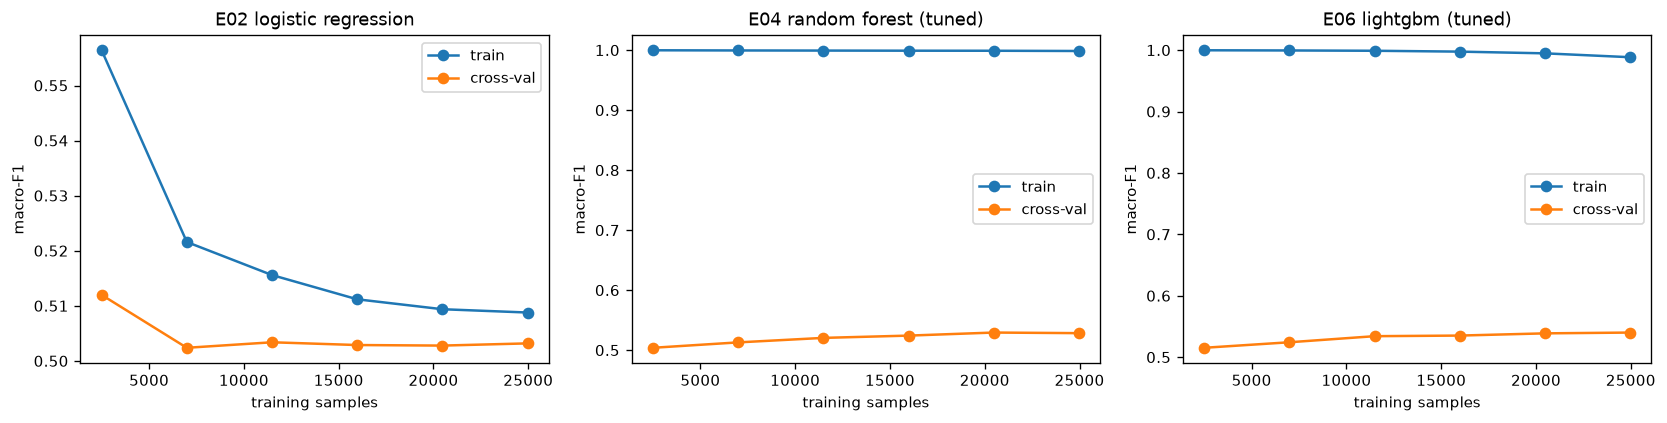

,train@max,cv@max,gap
E02 logistic regression,0.5088,0.5032,0.006
E04 random forest (tuned),0.9987,0.5285,0.470
E06 lightgbm (tuned),0.9886,0.5402,0.448


In [26]:
lc_models = {"E02 logistic regression": ml_results["E02"]["pipeline"],
             "E04 random forest (tuned)": ml_results["E04"]["pipeline"],
             "E06 lightgbm (tuned)": ml_results["E06"]["pipeline"]}
lc_data = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, pipe) in zip(axes, lc_models.items()):
    _, lc = plot_sklearn_learning_curve(pipe, split.X_train, split.y_train, name, cv=3, n_jobs=1)
    plt.close()
    lc_data[name] = lc
    ax.plot(lc["sizes"], lc["train"], "o-", label="train"); ax.plot(lc["sizes"], lc["val"], "o-", label="cross-val")
    ax.set(title=name, xlabel="training samples", ylabel="macro-F1"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig03_learning_curves_ml.png"); plt.show()
pd.DataFrame({k: {"train@max": v["train"][-1], "cv@max": v["val"][-1], "gap": round(v["train"][-1]-v["val"][-1], 3)} for k, v in lc_data.items()}).T

**Interpretation (bias–variance).** Logistic regression's curves converge at macro-F1 ≈ 0.50 with a
train–validation gap of 0.006: a bias-limited model that more data will not help. Both tree ensembles
score ≈ 1.0 on their training data and ≈ 0.53–0.54 in cross-validation, a gap of 0.45 that is textbook
variance; their cross-validation curves are still rising slowly at 25,000 rows, so more data would help
a little, and it was regularisation (leaf size, L2, subsampling) that closed part of the gap in E04 and
E06. The ceiling near 0.55 shared by every model points to irreducible error: the pre-determined
predictors do not contain what separates the unemployed from the other two states (timing of job
search, local labour demand).

## 4. Deep learning experiments (TensorFlow / Keras)

All networks are built with the **Functional API** (deep-learning helpers in Section 0), trained from
**`tf.data.Dataset`** pipelines (shuffle → batch → prefetch), optimised with Adam unless stated,
stopped early on validation loss (patience 10, best weights restored) and logged to **TensorBoard**
under `logs/<run_id>`. Start TensorBoard with `tensorboard --logdir logs/` to inspect every curve.

Two input representations are compared: the same one-hot design matrix used by the
scikit-learn models (`dense`), and an **entity-embedding** design in which each nominal variable
(e.g. the 30 districts) is mapped to a small learned vector (`embedding`).

In [27]:
# Dense inputs: reuse the fitted one-hot preprocessor
X_tr = prep.transform(split.X_train).astype(np.float32)
X_va = prep.transform(split.X_val).astype(np.float32)
X_te = prep.transform(split.X_test).astype(np.float32)
n_features = X_tr.shape[1]

# Embedding inputs: integer-coded nominals
prep_emb = build_preprocessor(numeric, nominal, onehot=False)
M_tr = prep_emb.fit_transform(split.X_train); M_va = prep_emb.transform(split.X_val); M_te = prep_emb.transform(split.X_test)
n_numeric = M_tr.shape[1] - len(nominal)
cardinalities = [len(c) for c in prep_emb.named_transformers_["cat"].named_steps["encode"].categories_]
emb_tr, emb_va, emb_te = (split_embedding_inputs(M, n_numeric, nominal) for M in (M_tr, M_va, M_te))
print("dense features:", n_features, "| numeric block:", n_numeric, "| nominal cardinalities:", cardinalities)

def run_dl(run_id, model, hyperparams, notes, inputs="dense", batch_size=256, lr=1e-3, optimizer="adam",
           weight_decay=0.0, class_weight=None, epochs=100, patience=10):
    set_seeds(SEED)
    if inputs == "dense":
        tr, va, te = (make_dataset(X, y, batch_size, shuffle=s) for X, y, s in [(X_tr, split.y_train, True), (X_va, split.y_val, False), (X_te, split.y_test, False)])
    else:
        tr, va, te = (make_dataset(X, y, batch_size, shuffle=s) for X, y, s in [(emb_tr, split.y_train, True), (emb_va, split.y_val, False), (emb_te, split.y_test, False)])
    compile_model(model, lr=lr, optimizer=optimizer, weight_decay=weight_decay)
    history, info = train(model, tr, va, run_id, epochs=epochs, patience=patience, class_weight=class_weight)
    p_va, p_te = predict_proba(model, va), predict_proba(model, te)
    val_m, test_m = compute_metrics(split.y_val, p_va.argmax(1), p_va), compute_metrics(split.y_test, p_te.argmax(1), p_te)
    hp = {**hyperparams, "inputs": inputs, "batch_size": batch_size, "lr": lr, "optimizer": optimizer, "params": model.count_params(),
          "epochs_run": info["epochs_run"], "best_epoch": info["best_epoch"]}
    log_experiment(run_id, "deep learning", model.name, hp, val_m, test_m, notes=notes, logdir=info["logdir"], train_time_s=info["train_time_s"])
    plot_keras_history(history, run_id, FIGURES_DIR / f"lc_{run_id}.png"); plt.show()
    print(f"[{run_id}] val {val_m} | epochs {info['epochs_run']} (best {info['best_epoch']}) | {info['train_time_s']:.0f}s")
    return {"model": model, "history": history, "val_metrics": val_m, "test_metrics": test_m, "val_proba": p_va, "test_proba": p_te, "info": info}

dl_results = {}

dense features: 191 | numeric block: 37 | nominal cardinalities: [5, 2, 30, 2, 13, 7, 9, 2, 2, 2, 2, 3, 7, 50, 5, 10, 14, 3, 2, 2, 3, 2]


### D01 — Plain MLP (2 × 128, no regularisation)
A minimal network establishes what a neural model does with the one-hot inputs before any
regularisation. With ~19k rows and ~180 inputs we expect it to overfit within a few epochs.

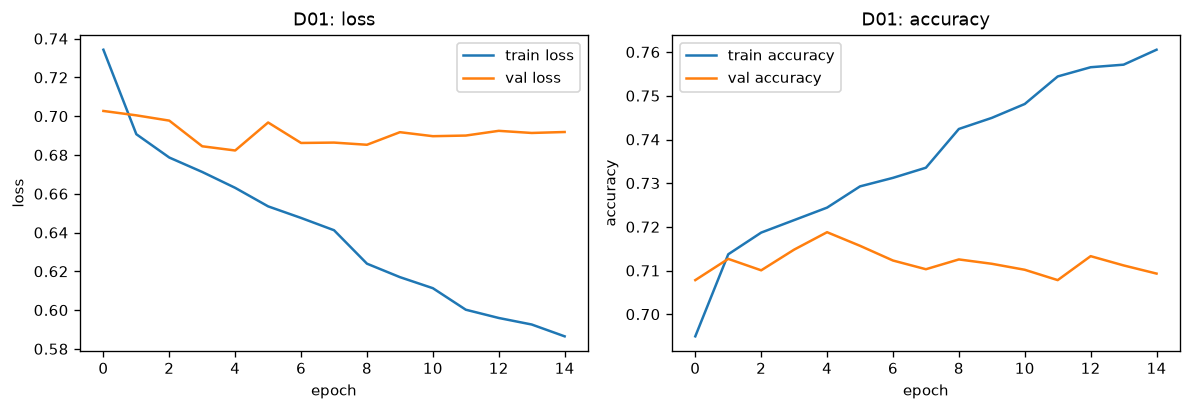

[D01] val {'accuracy': 0.7188, 'balanced_accuracy': 0.5342, 'f1_macro': 0.5209, 'f1_weighted': 0.6851, 'roc_auc_ovr_macro': 0.81, 'pr_auc_macro': 0.6245} | epochs 15 (best 5) | 5s


In [28]:
dl_results["D01"] = run_dl("D01", build_mlp(n_features, hidden=(128, 128), dropout=0.0, batch_norm=False, name="mlp_plain"),
                           {"hidden": (128, 128), "dropout": 0.0, "batch_norm": False}, "Unregularised baseline")

**Interpretation.** Without regularisation the validation loss bottoms out at epoch 5 and then rises
while the training loss keeps falling — overfitting in its plainest form. Early stopping restored the
epoch-5 weights, which is why the test score is still respectable (macro-F1 0.513).

### D02 — MLP + dropout + batch normalisation (256 → 128)
Dropout (0.3) and batch normalisation are the two standard remedies for the overfitting seen in D01.

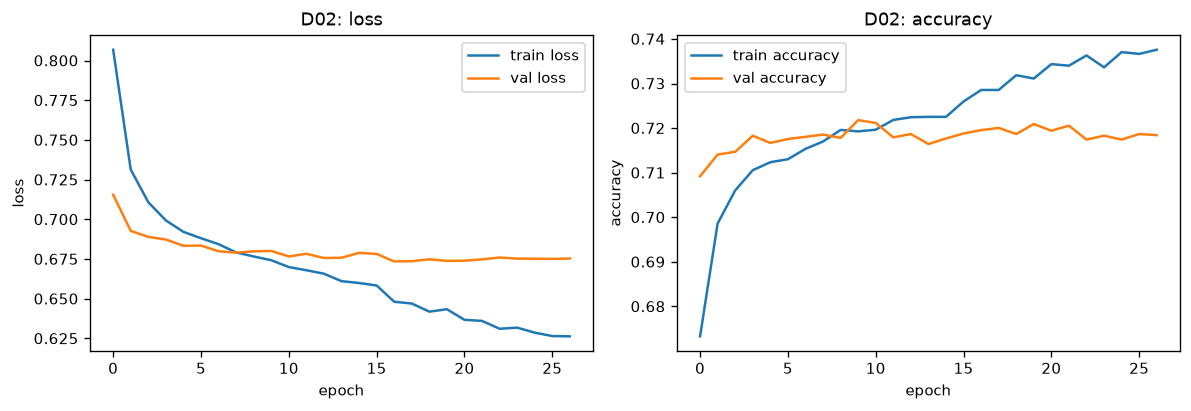

[D02] val {'accuracy': 0.7195, 'balanced_accuracy': 0.5424, 'f1_macro': 0.5357, 'f1_weighted': 0.6911, 'roc_auc_ovr_macro': 0.8159, 'pr_auc_macro': 0.6308} | epochs 27 (best 17) | 14s


In [29]:
dl_results["D02"] = run_dl("D02", build_mlp(n_features, hidden=(256, 128), dropout=0.3, batch_norm=True, name="mlp_reg"),
                           {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True}, "Adds dropout 0.3 + BN")

**Interpretation.** Dropout and batch normalisation delay the validation minimum to epoch 17 and lower
it (0.675 vs 0.683), lifting macro-F1 from 0.521 to 0.536 — the level of the untuned random forest.

### D03 — Deeper and wider (512 → 256 → 128, dropout 0.4)
Tests whether extra capacity helps once regularisation is in place, or whether the data simply
does not support a larger model.

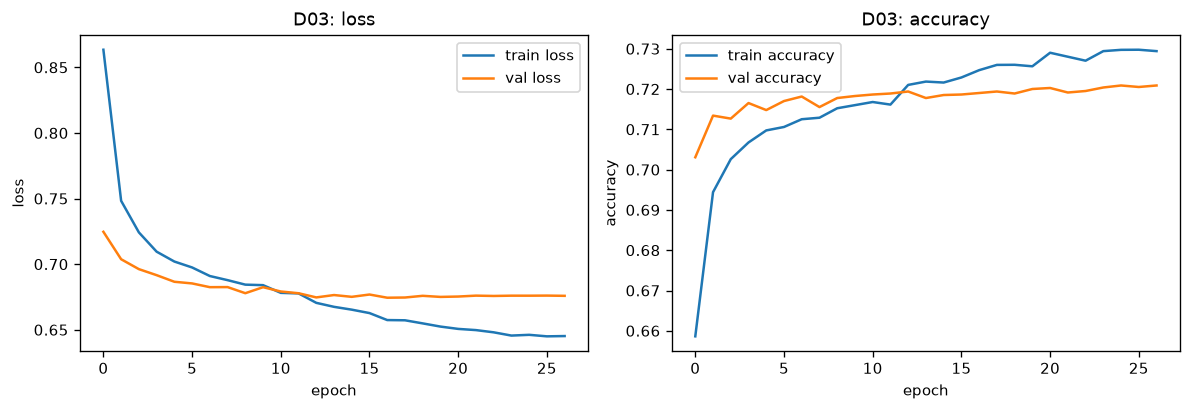

[D03] val {'accuracy': 0.719, 'balanced_accuracy': 0.5389, 'f1_macro': 0.5307, 'f1_weighted': 0.6893, 'roc_auc_ovr_macro': 0.8155, 'pr_auc_macro': 0.6313} | epochs 27 (best 17) | 68s


In [30]:
dl_results["D03"] = run_dl("D03", build_mlp(n_features, hidden=(512, 256, 128), dropout=0.4, batch_norm=True, name="mlp_deep"),
                           {"hidden": (512, 256, 128), "dropout": 0.4, "batch_norm": True}, "Capacity test")

**Interpretation.** Tripling the parameters to 267k changes nothing on validation (macro-F1 0.531): the
data, not the capacity, is the constraint — the same conclusion the learning curves gave for the trees.

### D04 — Learning-rate sweep (D02 architecture at 1e-2 and 1e-4)
The learning rate is the single most influential optimiser setting. A rate ten times higher than
the default should produce noisy or diverging validation loss; ten times lower should learn slowly
and may stop early before converging.

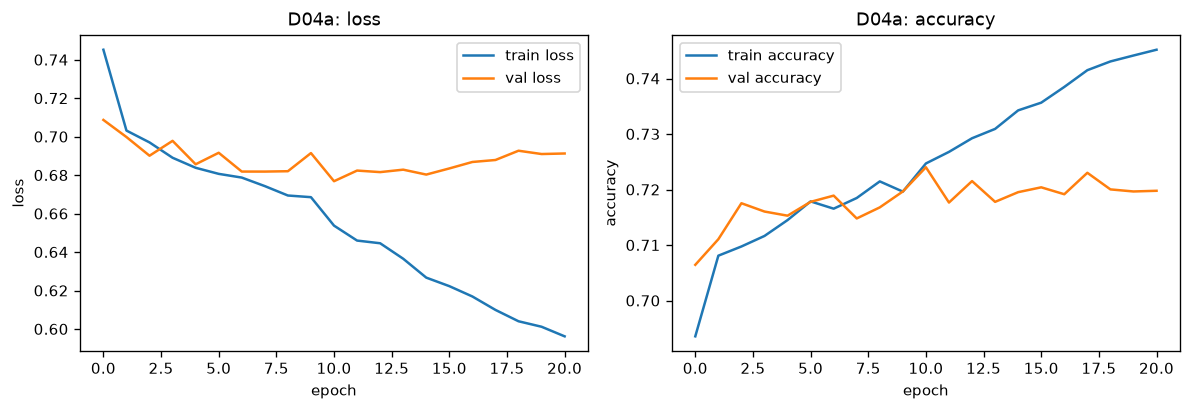

[D04a] val {'accuracy': 0.724, 'balanced_accuracy': 0.5458, 'f1_macro': 0.54, 'f1_weighted': 0.6947, 'roc_auc_ovr_macro': 0.8132, 'pr_auc_macro': 0.6311} | epochs 21 (best 11) | 11s


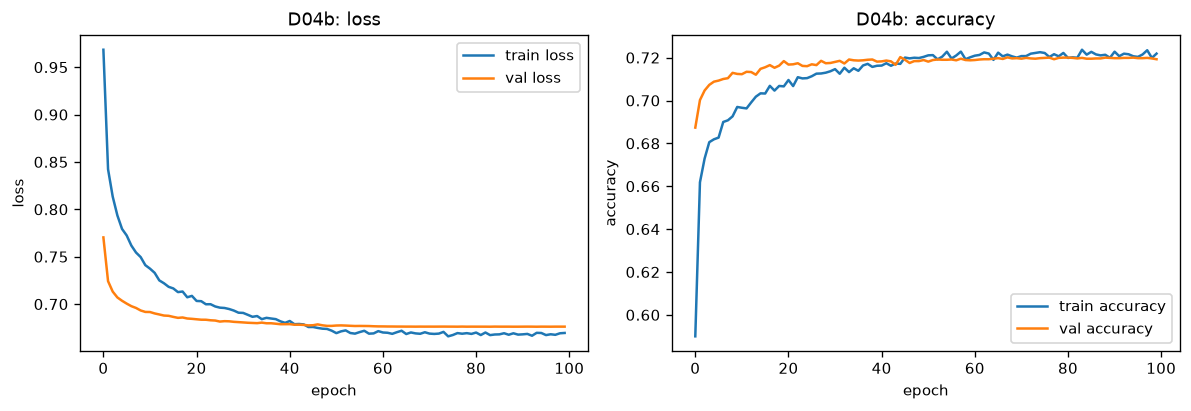

[D04b] val {'accuracy': 0.7199, 'balanced_accuracy': 0.5374, 'f1_macro': 0.5262, 'f1_weighted': 0.6885, 'roc_auc_ovr_macro': 0.8139, 'pr_auc_macro': 0.6275} | epochs 100 (best 94) | 50s


In [31]:
dl_results["D04a"] = run_dl("D04a", build_mlp(n_features, hidden=(256, 128), dropout=0.3, batch_norm=True, name="mlp_reg_lr1e-2"),
                            {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True}, "D02 with lr=1e-2", lr=1e-2)
dl_results["D04b"] = run_dl("D04b", build_mlp(n_features, hidden=(256, 128), dropout=0.3, batch_norm=True, name="mlp_reg_lr1e-4"),
                            {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True}, "D02 with lr=1e-4", lr=1e-4)

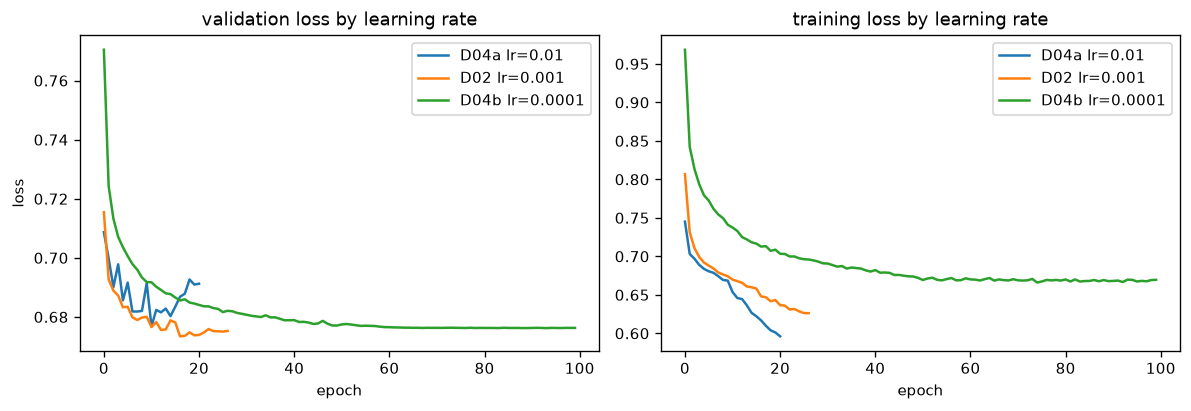

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for rid in ["D04a", "D02", "D04b"]:
    h = dl_results[rid]["history"]; lr_ = json.loads(load_experiments().set_index("run_id").loc[rid, "hyperparams"])["lr"]
    axes[0].plot(h["val_loss"], label=f"{rid} lr={lr_}"); axes[1].plot(h["loss"], label=f"{rid} lr={lr_}")
axes[0].set(title="validation loss by learning rate", xlabel="epoch", ylabel="loss"); axes[1].set(title="training loss by learning rate", xlabel="epoch")
axes[0].legend(); axes[1].legend(); fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig04_lr_sweep.png"); plt.show()

**Interpretation.** At 10⁻² the validation loss oscillates by about ±0.01 from epoch to epoch and the
run stops at epoch 21 with a slightly worse minimum; at 10⁻⁴ the loss descends smoothly but is still
falling at epoch 100 (best epoch 94) — too slow to converge within the budget; 10⁻³ reaches the lowest
loss fastest. The three end within 1.5 macro-F1 points of each other, so here the learning rate changes
the path much more than the destination.

### D05 — Entity-embedding MLP
Each nominal variable gets its own `Embedding` layer (dimension ≈ 1.6·n^0.56, capped at 16),
concatenated with the standardised numerics. Embeddings let the network learn that, say,
two districts have similar youth labour markets, which one-hot inputs cannot express.

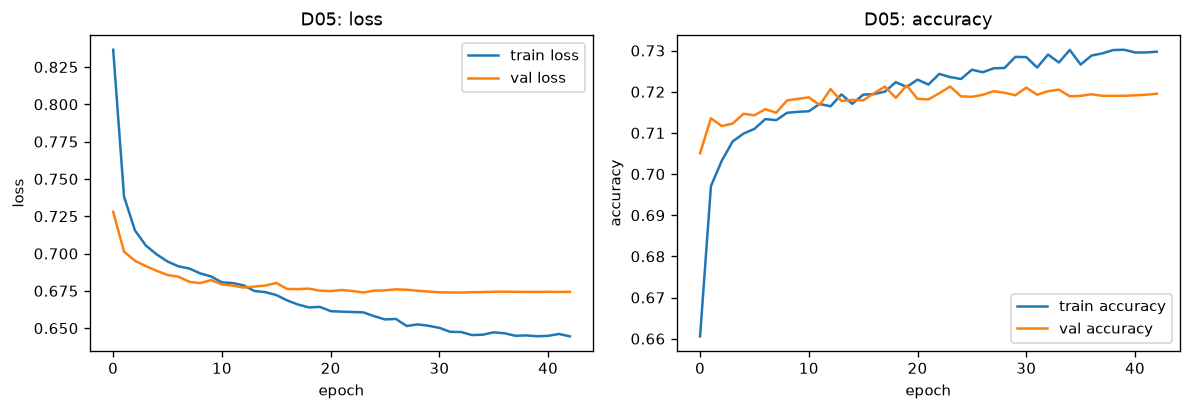

[D05] val {'accuracy': 0.7202, 'balanced_accuracy': 0.5428, 'f1_macro': 0.5367, 'f1_weighted': 0.6916, 'roc_auc_ovr_macro': 0.816, 'pr_auc_macro': 0.6314} | epochs 43 (best 33) | 71s


In [33]:
dl_results["D05"] = run_dl("D05", build_embedding_mlp(n_numeric, cardinalities, nominal, hidden=(256, 128), dropout=0.3, name="embedding_mlp"),
                           {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True, "embeddings": "per-nominal"}, "Entity embeddings instead of one-hot", inputs="embedding")

**Interpretation.** Entity embeddings match the one-hot network (0.537 vs 0.536) with fewer parameters
(70k vs 84k) but take longer to converge (best epoch 33). With only 30 districts and 50 TVET skills the
one-hot encoding is already compact; embeddings pay off when cardinalities are in the hundreds.

### D06 — Embedding MLP + class weights
The deep-learning counterpart of E08: inverse-frequency class weights in the loss.

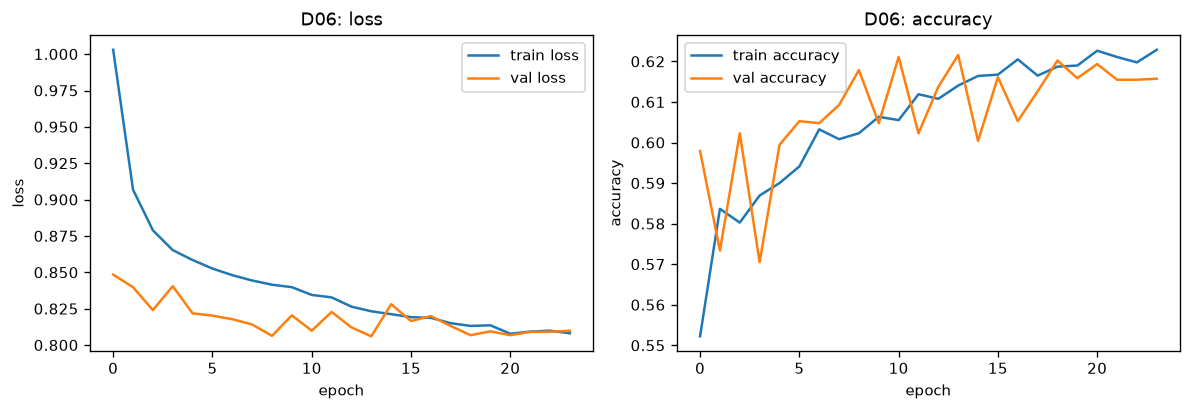

[D06] val {'accuracy': 0.6216, 'balanced_accuracy': 0.6124, 'f1_macro': 0.5669, 'f1_weighted': 0.661, 'roc_auc_ovr_macro': 0.8093, 'pr_auc_macro': 0.6238} | epochs 24 (best 14) | 22s


In [34]:
dl_results["D06"] = run_dl("D06", build_embedding_mlp(n_numeric, cardinalities, nominal, hidden=(256, 128), dropout=0.3, name="embedding_mlp_cw"),
                           {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True, "class_weight": "balanced"}, "D05 + balanced class weights",
                           inputs="embedding", class_weight=class_weights_from(split.y_train))

**Interpretation.** Class weights move the embedding network to balanced accuracy 0.612 and unemployed
recall 0.55 on the test set, at the cost of accuracy (0.622). It becomes the best deep run by macro-F1
(0.567), mirroring what E08 did for LightGBM. The validation loss is now noisier because each
unemployed example carries about five times the weight of an employed one.

### D07 — AdamW with weight decay and L2, larger batch
Decoupled weight decay (AdamW, 1e-4) plus L2 on the dense layers and a batch size of 512 — a
different regularisation route from dropout, with smoother gradient estimates.

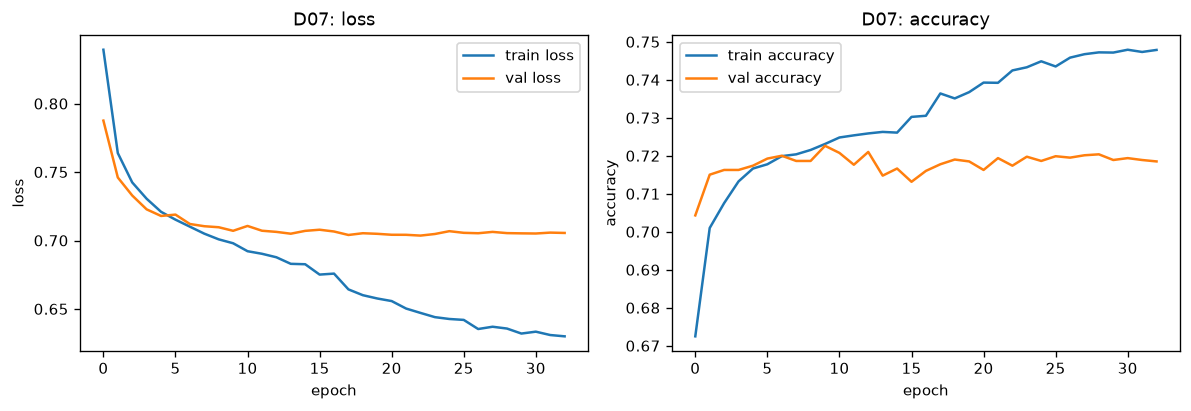

[D07] val {'accuracy': 0.7174, 'balanced_accuracy': 0.5464, 'f1_macro': 0.5437, 'f1_weighted': 0.6921, 'roc_auc_ovr_macro': 0.814, 'pr_auc_macro': 0.6301} | epochs 33 (best 23) | 15s


In [35]:
dl_results["D07"] = run_dl("D07", build_mlp(n_features, hidden=(256, 128), dropout=0.2, batch_norm=True, l2=1e-4, name="mlp_adamw"),
                           {"hidden": (256, 128), "dropout": 0.2, "batch_norm": True, "l2": 1e-4}, "AdamW + L2 + batch 512",
                           optimizer="adamw", weight_decay=1e-4, batch_size=512)

### D08 — SGD with momentum (optimiser comparison)
Replacing Adam with plain SGD + momentum (lr 0.05) on the D02 architecture isolates the optimiser's
role; SGD typically needs more epochs but can generalise comparably.

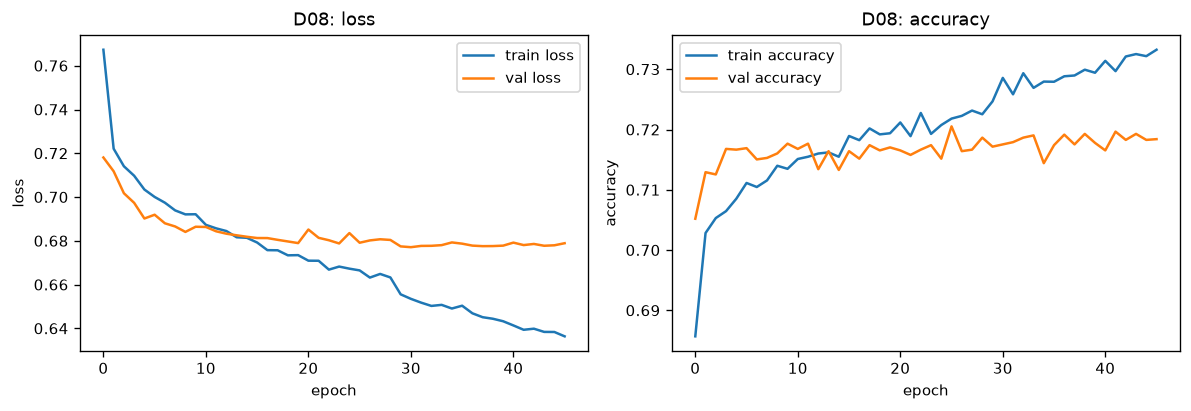

[D08] val {'accuracy': 0.7175, 'balanced_accuracy': 0.5396, 'f1_macro': 0.5322, 'f1_weighted': 0.6877, 'roc_auc_ovr_macro': 0.8118, 'pr_auc_macro': 0.6281} | epochs 46 (best 31) | 23s


In [36]:
dl_results["D08"] = run_dl("D08", build_mlp(n_features, hidden=(256, 128), dropout=0.3, batch_norm=True, name="mlp_sgd"),
                           {"hidden": (256, 128), "dropout": 0.3, "batch_norm": True}, "D02 architecture, SGD momentum 0.9", optimizer="sgd", lr=0.05, epochs=150, patience=15)

**Interpretation.** AdamW with L2 (D07, 0.544) sits between D02 and D06 and shows the flattest validation
curve; SGD with momentum (D08) needs 46 epochs to reach what Adam reached in 27 and ends 0.4 points
lower. No optimiser or regulariser moves a dense network past the ≈ 0.54 ceiling without class weights.

## 5. Results

### 5.1 Experiment table
Every run above, with its hyper-parameters, validation and test metrics, training time and the
TensorBoard log directory backing it. The same table is saved to `reports/experiments.csv` and
`reports/experiment_table.md`.

In [37]:
exp = load_experiments()
cols = ["run_id", "approach", "model", "features", "val_accuracy", "val_balanced_accuracy", "val_f1_macro", "val_roc_auc_ovr_macro",
        "test_accuracy", "test_balanced_accuracy", "test_f1_macro", "test_roc_auc_ovr_macro", "train_time_s", "notes"]
pd.set_option("display.max_colwidth", 60); pd.set_option("display.width", 200)
display(exp[cols])
exp[["run_id", "hyperparams"]].to_markdown(FIGURES_DIR.parent / "experiment_hyperparams.md", index=False)
exp[cols].to_markdown(FIGURES_DIR.parent / "experiment_table.md", index=False)

,run_id,approach,model,features,val_accuracy,val_balanced_accuracy,val_f1_macro,val_roc_auc_ovr_macro,test_accuracy,test_balanced_accuracy,test_f1_macro,test_roc_auc_ovr_macro,train_time_s,notes
0,E01,traditional ML,logistic_regression,base only,0.7063,0.5173,0.4980,0.7994,0.6950,0.5106,0.4935,0.7900,23.8,Linear baseline on raw variables
1,E02,traditional ML,logistic_regression,base+engineered,0.7073,0.5182,0.4994,0.7995,0.6959,0.5113,0.4941,0.7898,25.8,Adds 10 engineered features to E01
2,E03,traditional ML,random_forest,base+engineered,0.7238,0.5452,0.5393,0.8117,0.7160,0.5388,0.5316,0.8066,5.1,Default forest; expect high variance (train ≈ 1.0)
3,E04,traditional ML,random_forest,base+engineered,0.7249,0.5480,0.5432,0.8106,0.7129,0.5395,0.5345,0.8011,64.7,"RandomizedSearchCV(12, cv=3) over depth/leaf/max_features"
4,E05,traditional ML,xgboost,base+engineered,0.7234,0.5422,0.5353,0.8189,0.7167,0.5353,0.5253,0.8089,4.3,Hand-set boosting baseline
5,E06,traditional ML,lightgbm,base+engineered,0.7174,0.5493,0.5475,0.8101,0.7114,0.5451,0.5429,0.7964,6.2,"RandomizedSearchCV(15, cv=3) over leaves/lr/trees/regula..."
6,E07,traditional ML,svm_rbf,base+engineered,0.7057,0.5174,0.5001,0.7719,0.6969,0.5113,0.4934,0.7594,67.6,Kernel SVM on stratified 12000-row subsample; note train...
7,E08,traditional ML,lightgbm,base+engineered,0.6950,0.5707,0.5721,0.8075,0.6819,0.5549,0.5563,0.7922,6.1,E06 + balanced sample weights
8,E09,traditional ML,lightgbm,base+engineered+C01+C19,0.9905,0.9750,0.9799,0.9962,0.9878,0.9674,0.9739,0.9954,5.0,Leakage ablation — NOT a candidate model
9,D01,deep learning,mlp_plain,base+engineered,0.7188,0.5342,0.5209,0.8100,0.7102,0.5274,0.5127,0.8037,4.7,Unregularised baseline


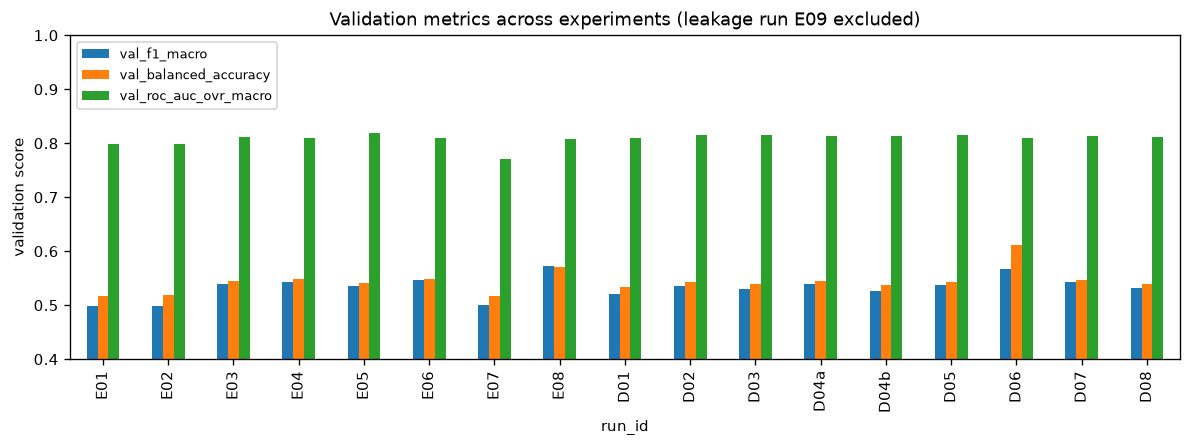

In [38]:
fig, ax = plt.subplots(figsize=(10, 3.8))
plot = exp[exp.run_id != "E09"].set_index("run_id")[["val_f1_macro", "val_balanced_accuracy", "val_roc_auc_ovr_macro"]]
plot.plot(kind="bar", ax=ax); ax.set(ylabel="validation score", title="Validation metrics across experiments (leakage run E09 excluded)"); ax.set_ylim(0.4, 1.0)
ax.legend(loc="upper left", fontsize=8); fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig05_experiment_comparison.png"); plt.show()

In [39]:
candidates = exp[exp.run_id != "E09"]
best_ml_id = candidates[candidates.approach == "traditional ML"].sort_values("val_f1_macro", ascending=False).iloc[0]["run_id"]
best_dl_id = candidates[candidates.approach == "deep learning"].sort_values("val_f1_macro", ascending=False).iloc[0]["run_id"]
print("Best traditional run by validation macro-F1:", best_ml_id, "| best deep-learning run:", best_dl_id)
best_ml, best_dl = ml_results[best_ml_id], dl_results[best_dl_id]
summary = pd.DataFrame({f"{best_ml_id} ({exp.set_index('run_id').loc[best_ml_id,'model']})": best_ml["test_metrics"],
                        f"{best_dl_id} ({exp.set_index('run_id').loc[best_dl_id,'model']})": best_dl["test_metrics"]})
display(summary)

Best traditional run by validation macro-F1: E08 | best deep-learning run: D06


,E08 (lightgbm),D06 (embedding_mlp_cw)
accuracy,0.6819,0.6091
balanced_accuracy,0.5549,0.5968
f1_macro,0.5563,0.5541
f1_weighted,0.6784,0.6473
roc_auc_ovr_macro,0.7922,0.7999
pr_auc_macro,0.6115,0.6157


### 5.2 Confusion matrices (test set)

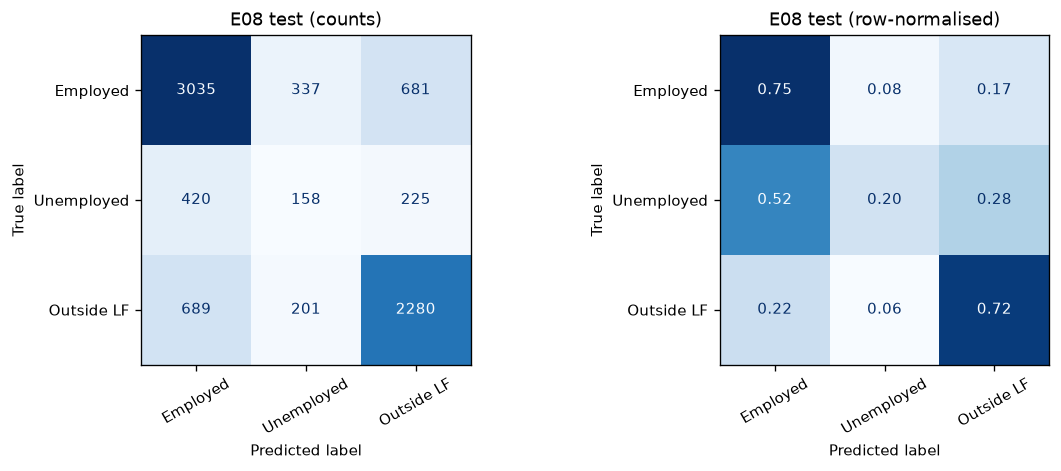

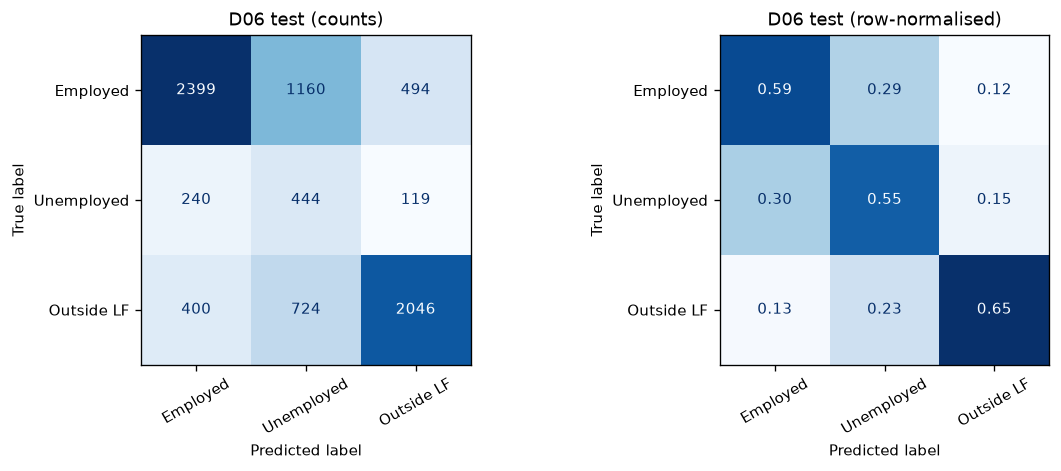

Per-class report — E08


,precision,recall,f1-score,support
Employed,0.732,0.749,0.741,4053.000
Unemployed,0.227,0.197,0.211,803.000
Outside labour force,0.716,0.719,0.717,3170.000
accuracy,0.682,0.682,0.682,0.682
macro avg,0.558,0.555,0.556,8026.000
weighted avg,0.675,0.682,0.678,8026.000


Per-class report — D06


,precision,recall,f1-score,support
Employed,0.789,0.592,0.677,4053.000
Unemployed,0.191,0.553,0.284,803.000
Outside labour force,0.769,0.645,0.702,3170.000
accuracy,0.609,0.609,0.609,0.609
macro avg,0.583,0.597,0.554,8026.000
weighted avg,0.722,0.609,0.647,8026.000


In [40]:
plot_confusion(split.y_test, best_ml["test_pred"], f"{best_ml_id} test", FIGURES_DIR / "fig06_confusion_best_ml.png"); plt.show()
plot_confusion(split.y_test, best_dl["test_proba"].argmax(1), f"{best_dl_id} test", FIGURES_DIR / "fig07_confusion_best_dl.png"); plt.show()
print("Per-class report —", best_ml_id); display(per_class_report(split.y_test, best_ml["test_pred"]))
print("Per-class report —", best_dl_id); display(per_class_report(split.y_test, best_dl["test_proba"].argmax(1)))

**Interpretation.** E08 recovers 75% of the employed and 72% of those outside the labour force but only
20% of the unemployed, over half of whom are labelled *employed*. D06 trades that around: 55%
unemployed recall, but 29% of the employed are now mislabelled as unemployed. These are two operating
points of models that rank almost identically (ROC-AUC 0.79–0.80); neither separates the unemployed
well because actively searching for work is not visible in the pre-determined predictors.

### 5.3 ROC and precision–recall curves (test set, one-vs-rest)

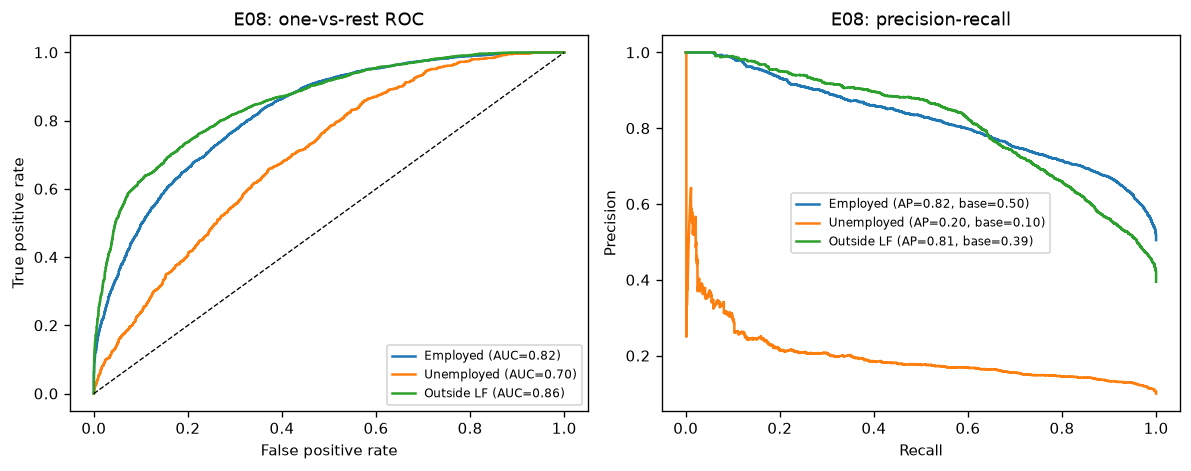

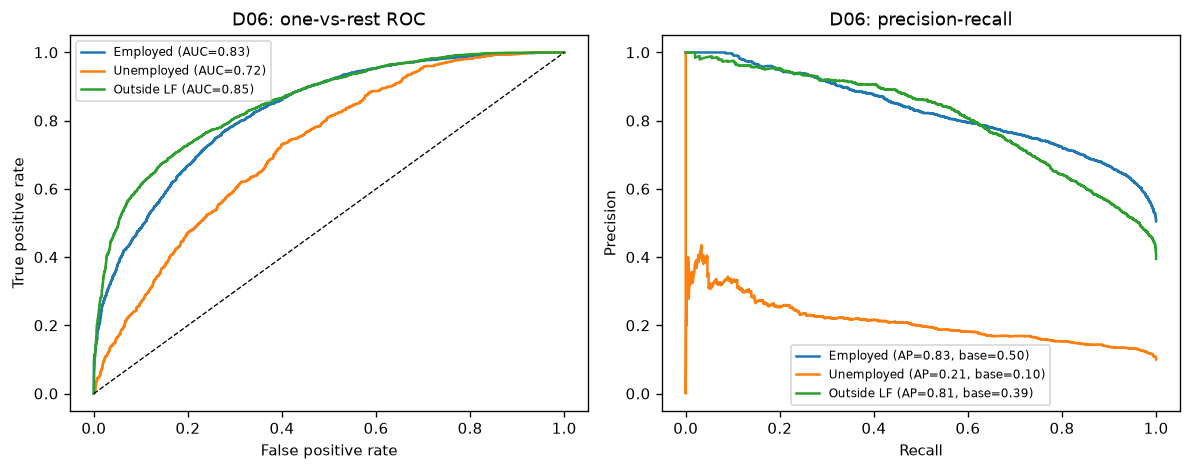

In [41]:
plot_roc_pr(split.y_test, best_ml["test_proba"], best_ml_id, FIGURES_DIR / "fig08_roc_pr_best_ml.png"); plt.show()
plot_roc_pr(split.y_test, best_dl["test_proba"], best_dl_id, FIGURES_DIR / "fig09_roc_pr_best_dl.png"); plt.show()

**Interpretation.** The one-vs-rest ROC curves are respectable for the two large classes (0.82 employed,
0.86 outside the labour force) but only 0.70 for the unemployed, and the precision–recall plot makes the
imbalance explicit: average precision 0.20 against a base rate of 0.10 — twice chance, not more. ROC-AUC
alone would have flattered the model, which is why macro-F1 and PR-AUC drive model selection.

### 5.4 Deep-learning learning curves side by side
Training and validation loss for the main architectures, read from the Keras histories (the same
curves are in TensorBoard).

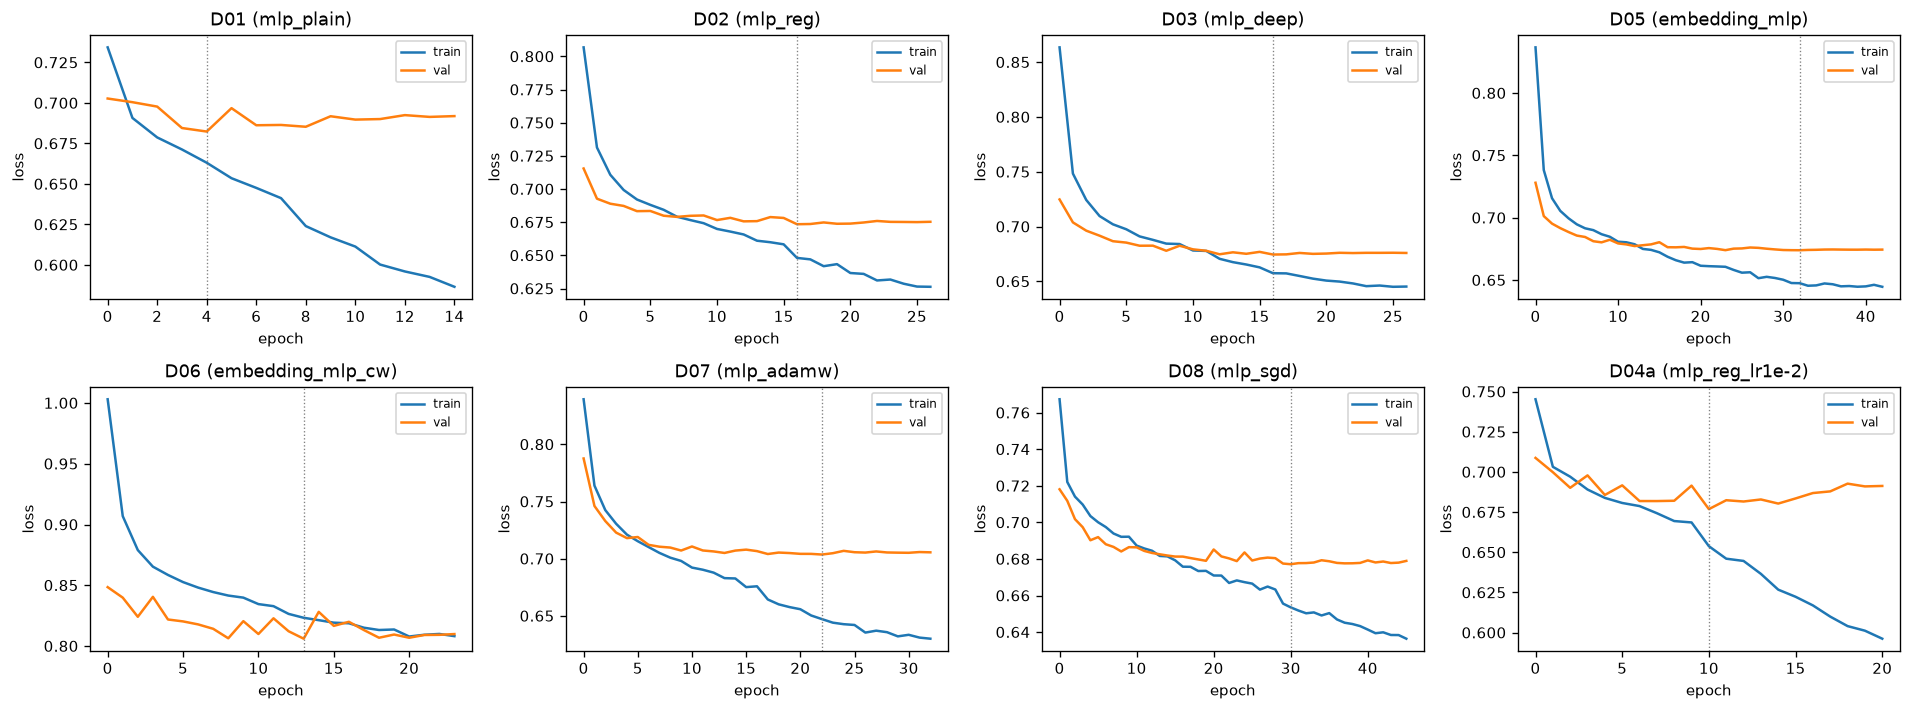

In [42]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, rid in zip(axes.ravel(), ["D01", "D02", "D03", "D05", "D06", "D07", "D08", "D04a"]):
    h = dl_results[rid]["history"]
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="val"); ax.axvline(dl_results[rid]["info"]["best_epoch"]-1, color="grey", ls=":", lw=0.8)
    ax.set(title=f"{rid} ({dl_results[rid]['model'].name})", xlabel="epoch", ylabel="loss"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig10_dl_learning_curves.png"); plt.show()

### 5.5 Which variables drive the predictions?
Permutation importance on the validation split for the best traditional model: each raw column is
shuffled in turn and the drop in macro-F1 recorded (mean of 5 repeats). Working on raw columns,
before one-hot expansion, keeps the result readable.

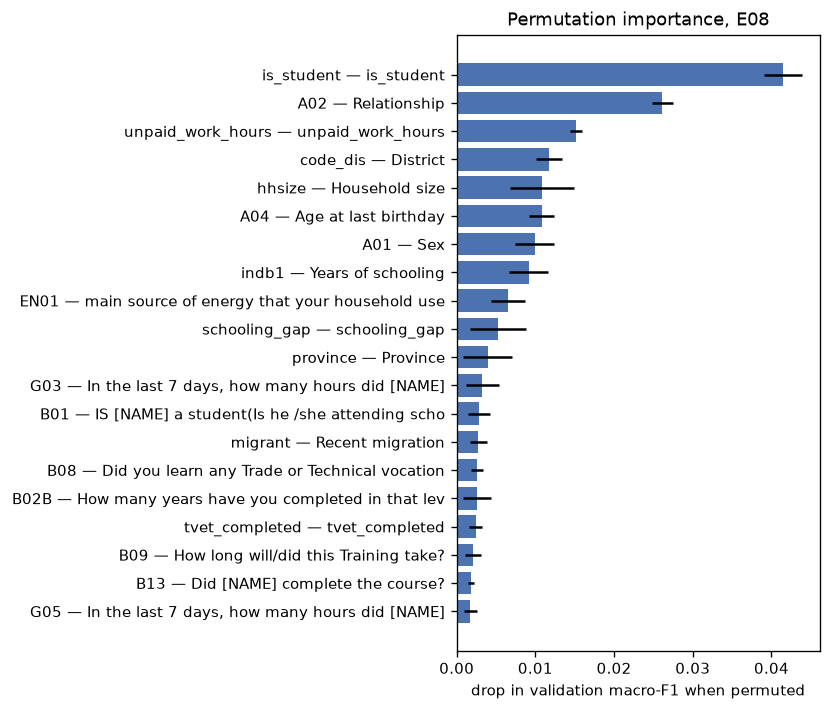

,feature,label,importance,std
28,is_student,is_student,0.0415,0.0024
36,A02,Relationship,0.0261,0.0013
23,unpaid_work_hours,unpaid_work_hours,0.0152,0.0008
34,code_dis,District,0.0117,0.0017
5,hhsize,Household size,0.0108,0.0041
0,A04,Age at last birthday,0.0108,0.0016
35,A01,Sex,0.0099,0.0025
4,indb1,Years of schooling,0.0091,0.0025
48,EN01,main source of energy that your household use,0.0065,0.0022
29,schooling_gap,schooling_gap,0.0053,0.0035


In [43]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_ml["pipeline"], split.X_val, split.y_val, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=1)
labels_map = {c: (meta.column_names_to_labels.get(c, c) or c)[:45] for c in split.X_val.columns}
imp = pd.DataFrame({"feature": split.X_val.columns, "label": [labels_map[c] for c in split.X_val.columns], "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(7, 6))
top = imp.head(20).iloc[::-1]
ax.barh(top["feature"] + " — " + top["label"], top["importance"], xerr=top["std"], color="#4C72B0")
ax.set(xlabel="drop in validation macro-F1 when permuted", title=f"Permutation importance, {best_ml_id}")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig11_permutation_importance.png"); plt.show()
imp.to_csv(FIGURES_DIR.parent / "permutation_importance.csv", index=False)
display(imp.head(12).round(4))

**Interpretation.** Being a student is the single most useful variable (0.041 macro-F1 drop), followed by
relationship to the household head, hours of unpaid work, district, household size, age, sex and years
of schooling. The TVET variables sit near the bottom. The model is largely learning the respondent's
life-course position — a child still in school, a spouse doing unpaid work, a head of household —
rather than skills, which is itself a finding for career programmes: training variables explain little
of *whether* a young person is working, in this survey.

### 5.6 Error analysis: where do the models fail?
Test-set accuracy of the best traditional model broken down by sex, residence, province,
education, studying and age group, and the most frequent confusions.

In [44]:
err = split.X_test.copy()
err["y_true"] = split.y_test; err["y_pred"] = best_ml["test_pred"]; err["correct"] = (err.y_true == err.y_pred)
vl = lambda col: pd.to_numeric(err[col], errors="coerce").map(meta.variable_value_labels[col])
err["sex"] = vl("A01"); err["residence"] = vl("Code_UR"); err["province"] = vl("province"); err["studying"] = vl("B01")
err["age group"] = vl("age3_16_30"); err["education"] = vl("B02A")
rows = []
for col in ["sex", "residence", "province", "education", "studying", "age group"]:
    g = err.groupby(col)["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "n"})
    g.index = [f"{col}: {i}" for i in g.index]; rows.append(g)
display(pd.concat(rows).round(3))

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(err.y_true, err.y_pred)
conf = [(TARGET_NAMES[i], TARGET_NAMES[j], int(cm[i, j]), round(cm[i, j] / cm[i].sum(), 3)) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j]
display(pd.DataFrame(conf, columns=["true", "predicted", "count", "share_of_true_class"]).sort_values("count", ascending=False))

,accuracy,n
sex: Female,0.628,4170
sex: Male,0.741,3856
residence: Rural,0.662,5156
residence: Urban,0.717,2870
province: City of Kigali,0.714,1327
province: Eastern Province,0.692,1848
province: Northern Province,0.676,1287
province: Southern Province,0.648,1822
province: Western Province,0.686,1742
education: Lower secondary education,0.710,2151


,true,predicted,count,share_of_true_class
4,Outside labour force,Employed,689,0.217
1,Employed,Outside labour force,681,0.168
2,Unemployed,Employed,420,0.523
0,Employed,Unemployed,337,0.083
3,Unemployed,Outside labour force,225,0.280
5,Outside labour force,Unemployed,201,0.063


unemployed_recall      n
sex    residence                          
Female Rural                  0.141  290.0
       Urban                  0.254  181.0
Male   Rural                  0.205  215.0
       Urban                  0.231  117.0

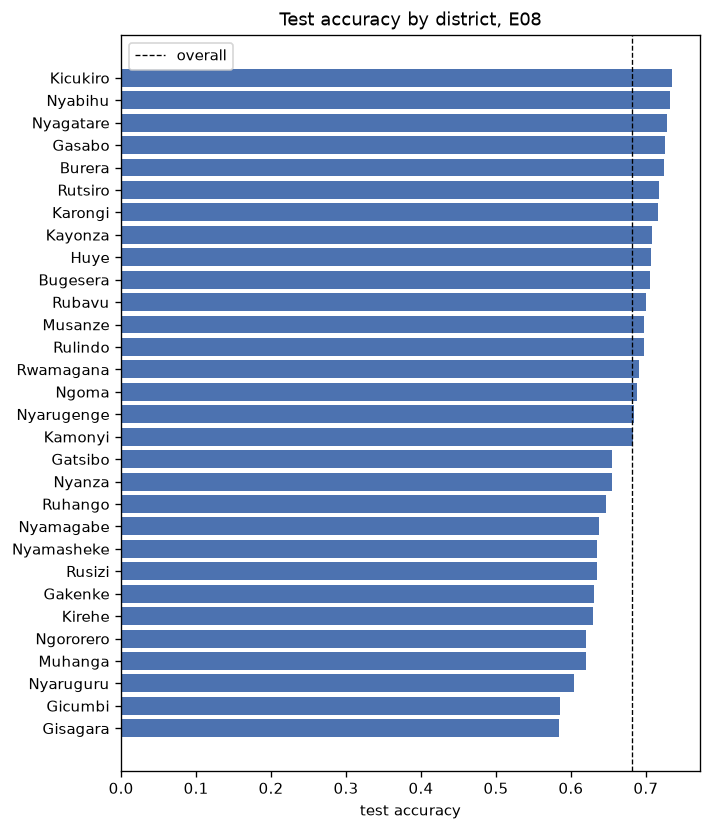

In [45]:
# Recall for the unemployed class by sex and residence: the policy-relevant failure mode
sub = err[err.y_true == 1]
rec = sub.groupby(["sex", "residence"]).apply(lambda g: pd.Series({"unemployed_recall": (g.y_pred == 1).mean(), "n": len(g)})).round(3)
display(rec)
dist_acc = err.assign(district=vl("code_dis")).groupby("district")["correct"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(6, 7)); ax.barh(dist_acc.index, dist_acc["mean"], color="#4C72B0"); ax.axvline(err["correct"].mean(), color="k", ls="--", lw=0.8, label="overall")
ax.set(xlabel="test accuracy", title=f"Test accuracy by district, {best_ml_id}"); ax.legend(); fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig12_accuracy_by_district.png"); plt.show()

**Interpretation.** Accuracy is 0.74 for men but 0.63 for women, 0.72 urban versus 0.66 rural, and
0.84 for students versus 0.63 for everyone else; district accuracy ranges from 0.58 (Gisagara) to 0.74
(Kicukiro). Recall on the unemployed class is lowest for rural women (0.14). The model is accurate where
status is institutionally fixed (students) and weak where it depends on informal activity: rural women
move between subsistence work, care and intermittent job search, and the survey's pre-determined
variables cannot tell those states apart.

## 6. Saving the best models
The best traditional pipeline (preprocessor + estimator) is saved with joblib; the best Keras model
in the native `.keras` format together with the fitted preprocessor it needs. These files are shared
through the Google Drive folder (they are git-ignored).

In [46]:
ml_path = MODELS_DIR / f"best_traditional_{best_ml_id}_{exp.set_index('run_id').loc[best_ml_id,'model']}.joblib"
joblib.dump(best_ml["pipeline"], ml_path)
dl_path = MODELS_DIR / f"best_deep_{best_dl_id}_{best_dl['model'].name}.keras"
best_dl["model"].save(dl_path)
joblib.dump({"dense": prep, "embedding": prep_emb, "numeric": numeric, "nominal": nominal, "n_numeric": n_numeric}, MODELS_DIR / "preprocessors.joblib")
print("saved:", ml_path.name, f"({ml_path.stat().st_size/1e6:.1f} MB) |", dl_path.name, f"({dl_path.stat().st_size/1e6:.1f} MB)")

# Reload check
re_ml = joblib.load(ml_path); re_dl = tf.keras.models.load_model(dl_path)
assert np.allclose(re_ml.predict_proba(split.X_test[:50]), best_ml["test_proba"][:50], atol=1e-6)
print("reload check passed")

saved: best_traditional_E08_lightgbm.joblib (16.7 MB) | best_deep_D06_embedding_mlp_cw.keras (1.1 MB)


reload check passed


## 7. Evidence of runs: TensorBoard and export

Every experiment wrote to `logs/<run_id>`: the Keras runs have per-epoch loss and accuracy curves, the
scikit-learn runs have their final validation metrics and hyper-parameters as scalar/text summaries.
Uncomment the magic below (locally or in Colab) to browse them; the screenshots used in the report
come from this dashboard. The logs are also zipped into `reports/tensorboard_logs.zip` and, on Colab,
everything is copied to the Drive folder.

In [47]:
# %load_ext tensorboard
# %tensorboard --logdir logs

In [48]:
import shutil
archive = shutil.make_archive(str(ROOT / "reports" / "tensorboard_logs"), "zip", LOGS_DIR)
print("TensorBoard logs archived:", Path(archive).name, f"({Path(archive).stat().st_size/1e6:.1f} MB)")
print("Run directories:", sorted(p.name for p in LOGS_DIR.iterdir()))

if IN_COLAB:
    out = drive_dir / "outputs"
    out.mkdir(parents=True, exist_ok=True)
    for src in ["reports", "models", "logs", "notebooks"]:
        shutil.copytree(src, out / src, dirs_exist_ok=True)
    print("Copied reports/, models/, logs/ and notebooks/ to", out)

TensorBoard logs archived: tensorboard_logs.zip (0.1 MB)
Run directories: ['D01', 'D02', 'D03', 'D04a', 'D04b', 'D05', 'D06', 'D07', 'D08', 'E01', 'E02', 'E03', 'E04', 'E05', 'E06', 'E07', 'E08', 'E09']


## 8. Conclusions

* **Eighteen logged experiments** on 53,503 young Rwandans (two LFS rounds) with a strict leakage rule.
  The best traditional model (E08, class-weighted LightGBM) reaches test macro-F1 0.556, balanced accuracy
  0.555 and ROC-AUC 0.79; the best deep model (D06, class-weighted embedding MLP) reaches 0.554, 0.597
  and 0.80. The paradigms tie on macro-F1 and ROC-AUC; the network gives higher unemployed recall, the
  boosting model higher accuracy, and boosting trains ten times faster.
* **Feature engineering** barely moved the linear model (+0.1 point) and none of the engineered columns
  entered the top permutation importances except `is_student` and `unpaid_work_hours`; the trees find
  the interactions on their own.
* **Learning curves** diagnose bias for the linear model and variance for the ensembles, with a shared
  ceiling around macro-F1 0.55 that no capacity, optimiser or learning rate crossed — irreducible error
  given the predictors.
* **Class imbalance** is the central difficulty: the unemployed (10%) get one-vs-rest ROC-AUC 0.70 and
  average precision 0.20. Class weighting is the only intervention that changed the error pattern, and
  it did so by trading accuracy for recall.
* **Error analysis** shows the model works where status is institutionally fixed (students, 84%) and
  fails for rural women (unemployed recall 14%), whose states are informal and shifting.
* **Leakage ablation** (E09, 99% accuracy) shows why the honest numbers look modest.
* **Limits and next steps**: the survey records no job-search history, local demand or networks, which
  are what distinguish the unemployed; quarterly panel structure (the LFS re-interviews households) could
  turn this into a transition model; and the evidence on TVET suggests that programme evaluation should
  look at job quality and earnings rather than employment status.

Saved artefacts: `models/best_traditional_E08_lightgbm.joblib`, `models/best_deep_D06_embedding_mlp_cw.keras`,
`reports/experiments.csv`, `reports/tensorboard_logs.zip`, `reports/figures/`.